# Intro

Welcome to the interactive tracking notebook!\
This notebook goes through each step and allows you to tune parameters and view how it changes the results.

The notebook proceeds as follows:
1. **Import** libraries
2. Define **paths** to data
3. Run data through the **pipeline**. Each step of the pipeline is run by a single unique python class.
4. **Visualize** results
5. **Save** results

As you go through the notebook, take note of the small number of parameters that are mentioned as **'important parameters'** (consider searching for these in the notebook). We consider these to be the only parameters that can have a large effect on the run output. Other parameters matter and should be considered as well, but are less critical.

##### If running on google colab:

- install roicat

After running the cell below, the runtime will restart.

In [1]:
#@title Install `roicat` if on colab
using_colab = 'google.colab' in str(get_ipython())

if using_colab:
    !pip uninstall -y tensorflow
    !pip install roicat[all]

- mount google drive

In [2]:
#@title mount gdrive if on colab
#@markdown Upload your data to Google Drive, then mount the drive and access the cloud directory here.
#@markdown You can use the sidebar to the left to browse your google drive directories.

using_colab = 'google.colab' in str(get_ipython())

if using_colab:
    from google.colab import drive
    path_gdrive = '/content/gdrive'
    drive.mount(path_gdrive, force_remount=True)

- enable widgets

In [3]:
if using_colab:
    from google.colab import output
    output.enable_custom_widget_manager()

# Import libraries

PyCharm-compatible display setup (no browser CSS required)

In [4]:
# PyCharm controls the notebook width; browser CSS output is not needed.

Import basic libraries

In [5]:
from pathlib import Path
import multiprocessing as mp
import tempfile

import numpy as np
import matplotlib

Import `roicat`

In [6]:
import roicat
import matplotlib.pyplot as plt
from tqdm.std import tqdm as tqdm_text

# tqdm.auto selects web widgets in a notebook kernel, including PyCharm.
# Use text progress for ROICaT in this kernel without changing the library.
for module in (
    roicat.helpers, roicat.util, roicat.data_importing, roicat.ROInet,
    roicat.tracking.alignment, roicat.tracking.clustering,
    roicat.tracking.similarity_graph, roicat.tracking.scatteringWaveletTransformer,
):
    module.tqdm = tqdm_text

def show_image_stack(images, clim=None, start=0, count=16):
    """Show a native image grid. Change start/count to inspect another range."""
    stop = min(start + count, len(images))
    if not 0 <= start < stop:
        raise ValueError('Choose a nonempty image range within the stack.')
    columns = min(4, stop - start)
    rows = (stop - start + columns - 1) // columns
    fig, axes = roicat.helpers.plot_image_grid(
        images=images[start:stop],
        labels=[f'Image {i}' for i in range(start, stop)],
        grid_shape=(rows, columns), cmap='gray',
        kwargs_subplots={'figsize': (3 * columns, 3 * rows), 'layout': 'constrained'},
        kwargs_imshow={} if clim is None else {'vmin': clim[0], 'vmax': clim[1]},
    )
    for ax in np.asarray(axes).ravel():
        ax.axis('off')
    print(f'Images {start}–{stop - 1} of {len(images)}. Use start= and count= to view another range.')
    plt.show()

# Find paths to data

In this example we are using suite2p output files, but other data types can be used (CaImAn, etc.) \
See the notebook on ingesting diverse data: https://github.com/RichieHakim/ROICaT/blob/main/notebooks/other/demo_data_importing.ipynb

Make a list containing the paths to all the input files.

In this example we are using suite2p, so the following are defined:
1. `paths_allStat`: a list to all the stat.npy files
2. `paths_allOps`: a list with ops.npy files that correspond 1-to-1 with the stat.npy files

In [7]:
dir_allOuterFolders = r'/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0'

pathSuffixToStat = 'stat.npy'
pathSuffixToOps = 'ops.npy'

paths_allStat = roicat.helpers.find_paths(
    dir_outer=dir_allOuterFolders,
    reMatch=pathSuffixToStat,
    depth=10,
)[:]
paths_allOps  = [str(Path(path).resolve().parent / pathSuffixToOps) for path in paths_allStat]

print(f'paths to all stat files:');
[print(path) for path in paths_allStat];
print('');
print(f'paths to all ops files:');
[print(path) for path in paths_allOps];

paths to all stat files:
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D1/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D2/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D3/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D4/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D5/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D6/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D7/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D8/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D9/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D10/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D11/stat.npy
/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D12/stat.npy
/Users/cemal/Downloads/data__stat_op

# Import data

**Important parameters**:
- `um_per_pixel` (float):
    - Resolution. 'micrometers per pixel' of the imaging field of view.

In [8]:
data = roicat.data_importing.Data_suite2p(
    paths_statFiles=paths_allStat[:],
    paths_opsFiles=paths_allOps[:],
    um_per_pixel=1.0,  ## IMPORTANT PARAMETER. Use a list of floats if values differ in each session.
    new_or_old_suite2p='new',
    type_meanImg='meanImgE',
    verbose=True,
)

assert data.check_completeness(verbose=False)['tracking'], f"Data object is missing attributes necessary for tracking."

Starting: Importing FOV images from ops files
Completed: Set FOV_height and FOV_width successfully.
Completed: Imported 14 FOV images.
Setting FOV_images...
Completed: Set FOV_images for 14 sessions successfully.
Importing spatial footprints from stat files.


100%|██████████| 14/14 [00:00<00:00, 37.21it/s]


Imported 14 sessions of spatial footprints into sparse arrays.
Completed: Created session_bool.
Completed: Set spatialFootprints for 14 sessions successfully.
Completed: Created centroids.
Starting: Creating centered ROI images from spatial footprints...
Completed: Created ROI images.


**Note on subselecting ROIs**:

Generally, I recommend the following:
- Do not subselecting ROIs prior to tracking. Use all available ROIs for the entire tracking process.
- Then, after tracking, subsequently apply classification and inclusion criteria to remove bad ROIs. See the 'tracking_handling_outputs.ipynb' notebook for details.

However, if you want to subselect ROIs before tracking you can call `data.remove_ROIs_by_classLabel()`. Prior to doing this, you will first need to set the class labels in the `data` object by either calling `data.set_class_labels()` or providing the `paths_iscell` input argument (if using the `Data_suite2p` class). Code below:

```python
data.remove_rois_by_classLabel(classLabel_to_keep=1, verbose=True)
```

Images 0–13 of 14. Use start= and count= to view another range.


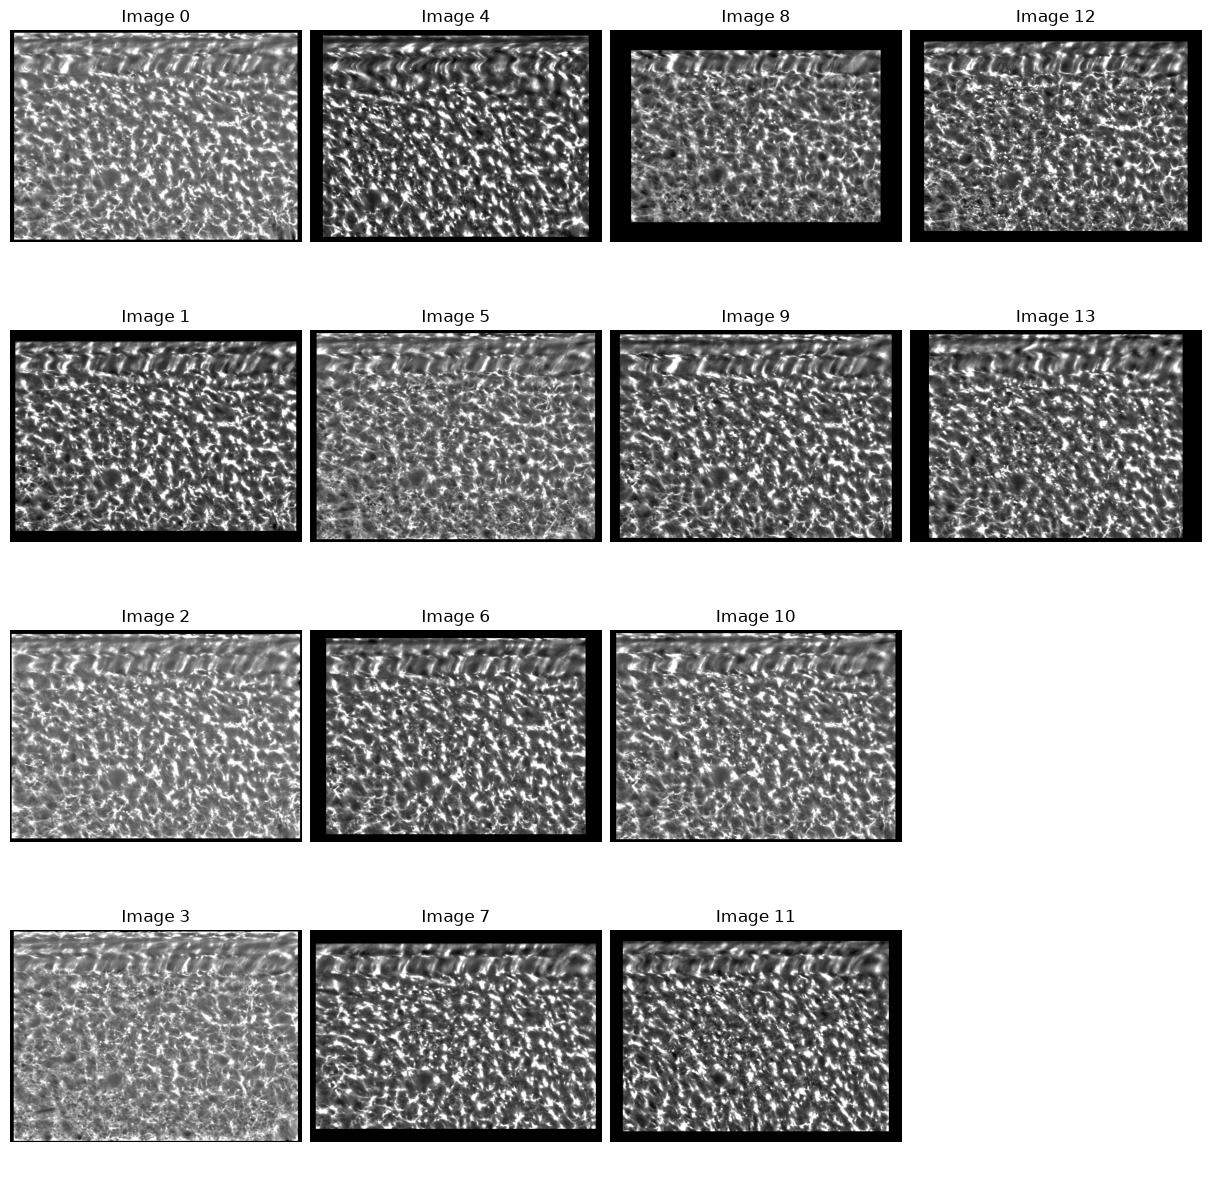

Images 0–13 of 14. Use start= and count= to view another range.


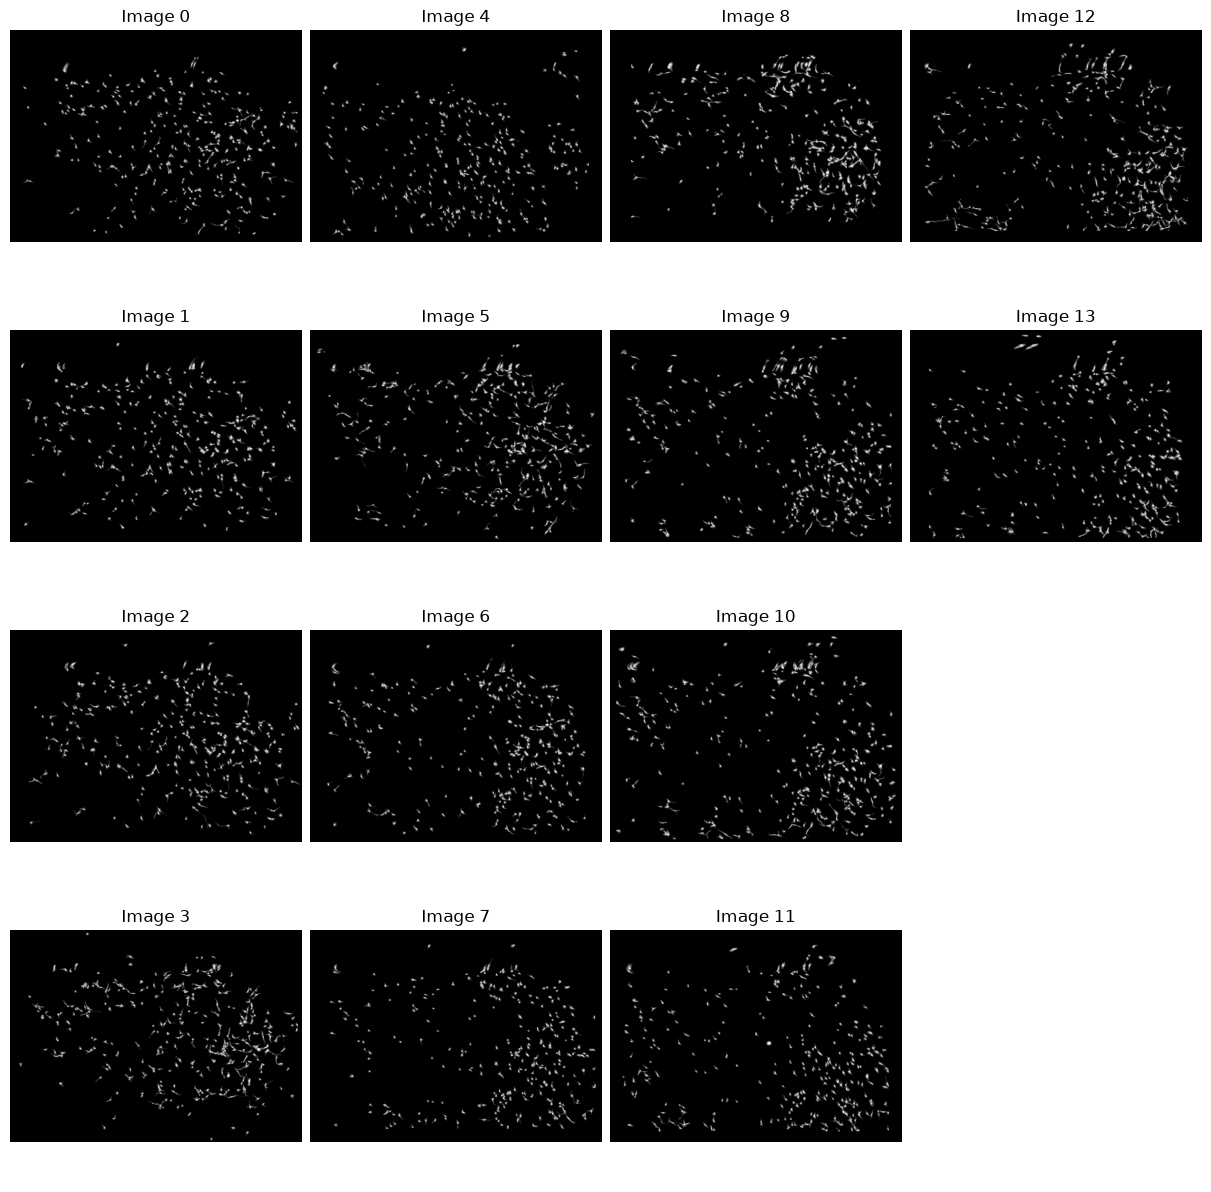

Images 0–15 of 4200. Use start= and count= to view another range.


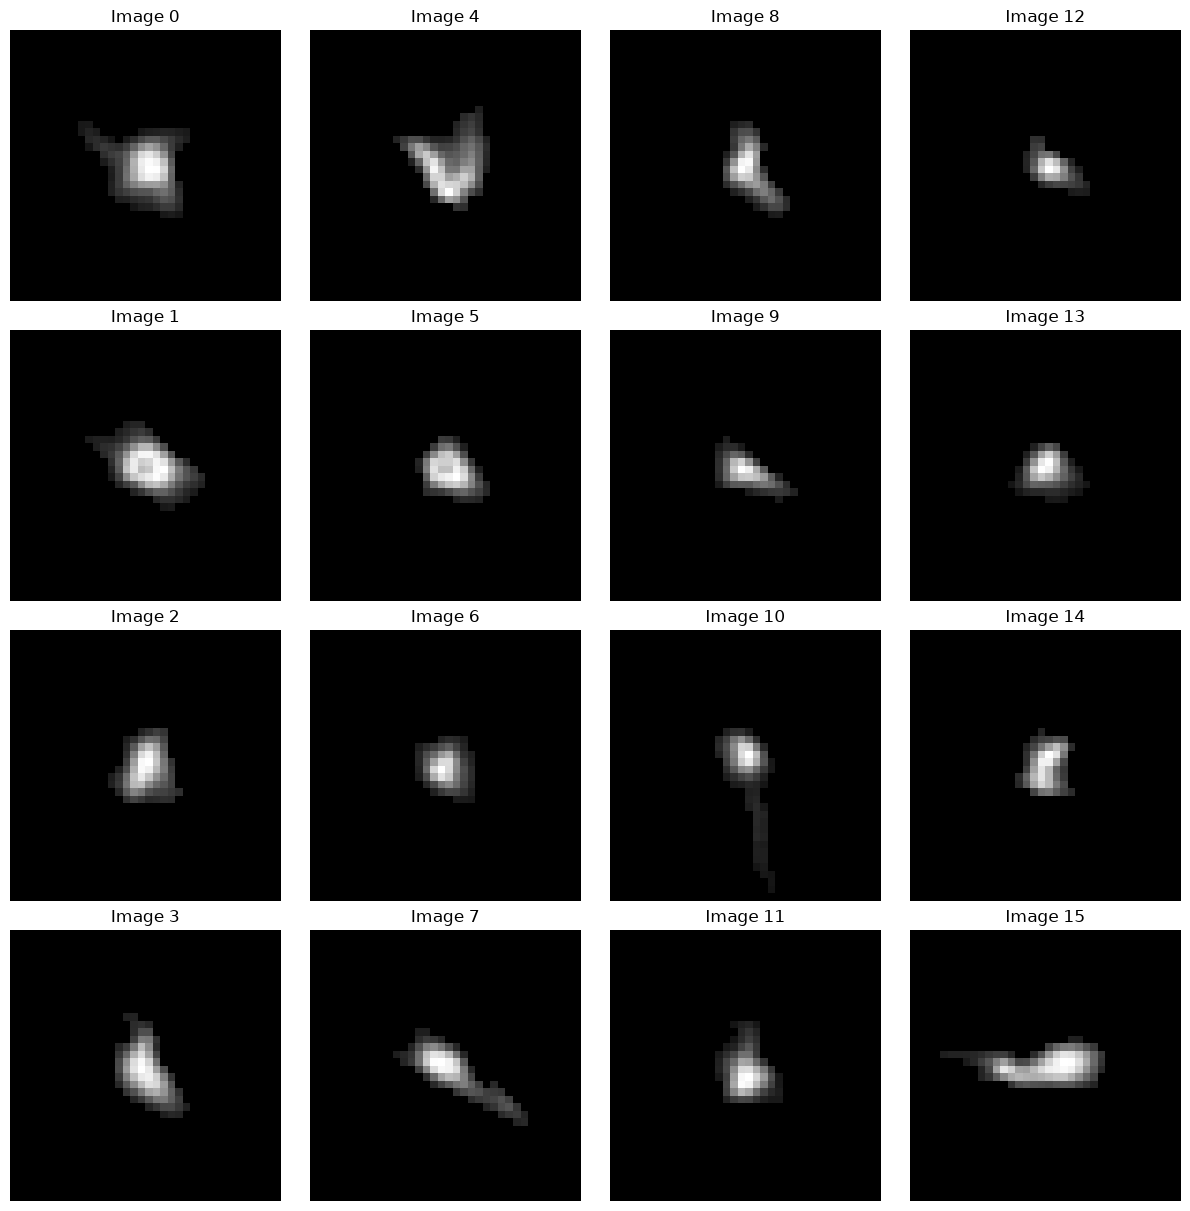

In [9]:
show_image_stack(data.FOV_images)
show_image_stack(data.get_maxIntensityProjection_spatialFootprints(), clim=[0,1])
show_image_stack(np.concatenate(data.ROI_images, axis=0)[:5000])

### Set the device to run on

If you have a GPU, some steps can be sped up.

In [10]:
DEVICE = roicat.helpers.set_device(use_GPU=True)

Using device: mps:0


### Set determinism and seed
Perfect determinism is not possible for a variety of reasons, but by setting `deterministic` to True you can get close by forcing the backend code to use deterministic algorithms where possible. It is generally not recommended to use deterministic algorithms and seeds due to the potential for reproducing low probability outputs and slower computation. Though, it can be useful in recreating bugs. If you want to do so, you can set the `deterministic` parameter to `True` below.

In [11]:
SEED = roicat.util.set_random_seed(seed=None, deterministic=False)  ## Deterministic algorithms have issues, but are useful for debugging, testing, and reproducing results.

# Alignment

This is the most important step in the pipeline to stop and check that everything looks okay and tune parameters if necessary.

Alignment is 4 steps:

1. FOV_image augmentation
2. Fit geometric transformation
3. Fit non-rigid transformation (on top of the geometric)
4. Apply transformation to ROIs

##### 1. FOV_image augmentation
Do what is necessary to make the augmented FOV_images look good. Use the visualization tool below to help. This can include playing with the mixing factor, normalization, and playing with the CLAHE parameters.

In [12]:
aligner = roicat.tracking.alignment.Aligner(
    use_match_search=True,  ## Use our algorithm for doing all-pairs matching if template matching fails.
    all_to_all=False,  ## Force the use of our algorithm for all-pairs matching. Much slower (False: O(N) vs. True: O(N^2)), but more accurate.
    radius_in=4,  ## IMPORTANT PARAMETER: Value in micrometers used to define the maximum shift/offset between two images that are considered to be aligned. Larger means more lenient alignment.
    radius_out=20,  ## Value in micrometers used to define the minimum shift/offset between two images that are considered to be misaligned.
    z_threshold=4.0,  ## IMPORTANT PARAMETER: Z-score required to define two images as aligned. Larger values results in more stringent alignment requirements.
    um_per_pixel=data.um_per_pixel[0],  ## Single value for um_per_pixel. data.um_per_pixel is typically a list of floats, so index out just one value.
    device=DEVICE,
    verbose=True,
)

In [13]:
FOV_images = aligner.augment_FOV_images(
    FOV_images=data.FOV_images,
    spatialFootprints=data.spatialFootprints,
    normalize_FOV_intensities=True,
    roi_FOV_mixing_factor=0.5,
    use_CLAHE=False,  ## Whether to apply CLAHE.
    CLAHE_grid_block_size=10,  ## IMPORTANT PARAMETER. Use smaller values for higher precision but higher chance of failure.
    CLAHE_clipLimit=1.0,
    CLAHE_normalize=True,
    local_norm_sigma_um=12.0,  ## Standard deviation in micrometers of the Gaussian window for the local brightness normalization. Should be roughly the diameter of a cell body. None turns it off.
)

Normalizing local brightness: sigma = 12.00 px (12.0 um / 1.0 um per pixel)


View the augmented FOV images

Images 0–13 of 14. Use start= and count= to view another range.


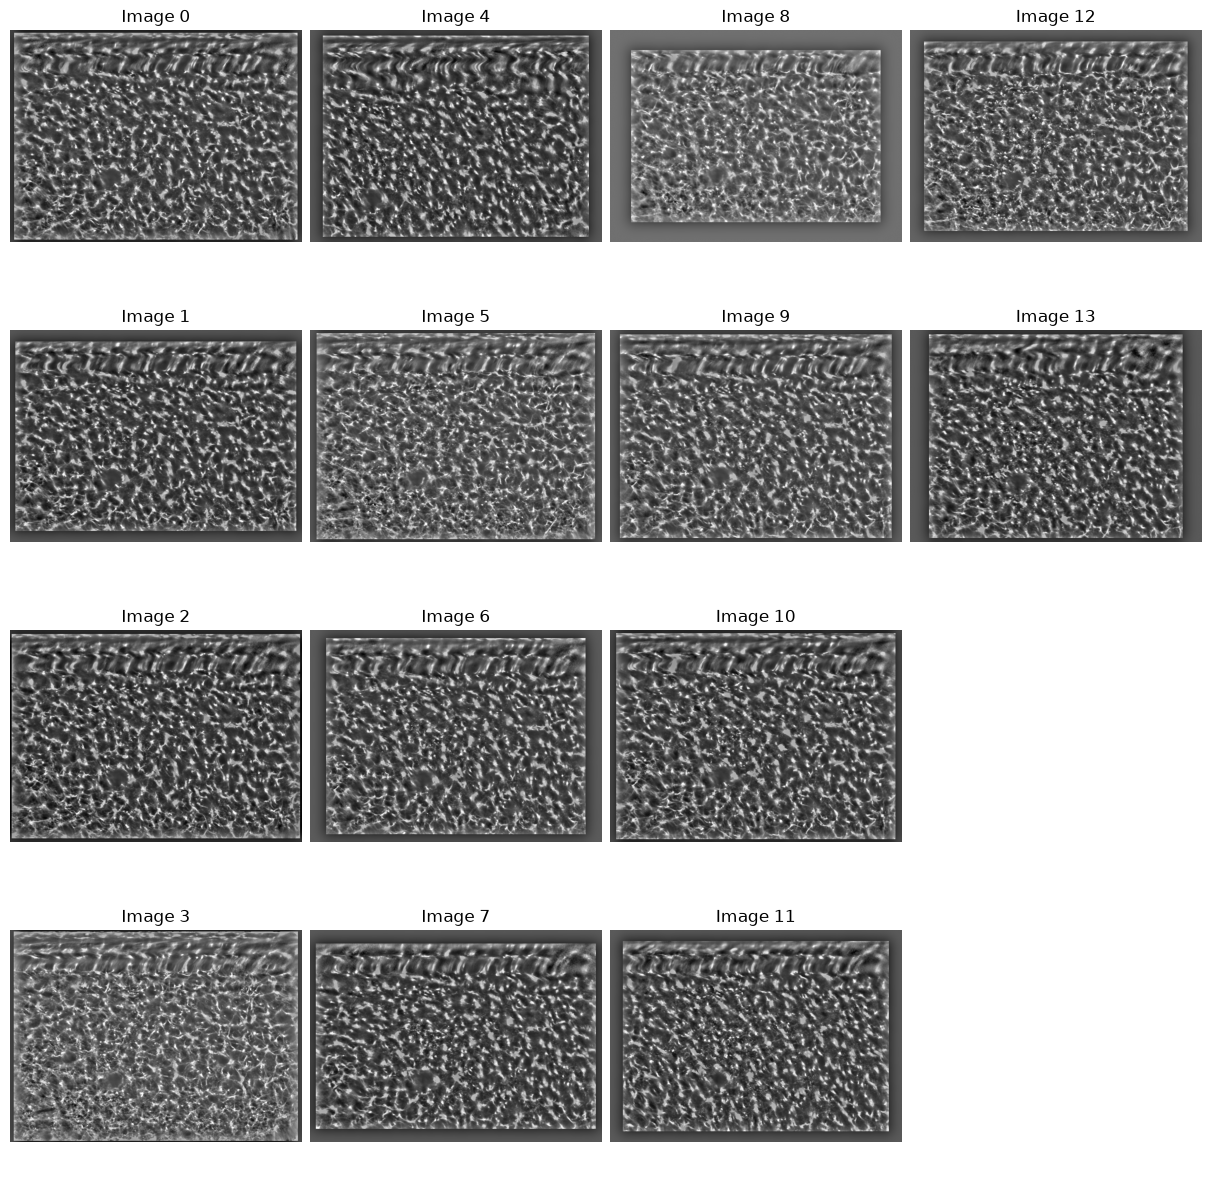

In [14]:
show_image_stack(FOV_images)

##### 2. Fit geometric transformation
This is an important step. Consider reading the comments and arguments closely.

Play with parameters until the aligned FOV_images look good. The visualization tool below can help.

This step creates the attribute: `aligner.ims_registered_geo`, which are the registered images after the geometric transformation.

We like the following **important parameters**:
- `template=0` for this Valerio demo (D1). The previous middle-session reference left D4 below the alignment threshold.
- `method='RoMa'` if you have a GPU, otherwise use one of the other methods
- `template_method='sequential'` best if there are large changes that occurrs slowly over sessions

In [15]:
aligner.fit_geometric(
    template=0,  ## D1 is the reference for this demo; keep the same reference in fit_nonrigid.
    ims_moving=FOV_images,  ## input images
    template_method='sequential',  ## 'sequential': align images to neighboring images (good for drifting data). 'image': align to a single image
    mask_borders=(0, 0, 0, 0),  ## number of pixels to mask off the edges (top, bottom, left, right)
    method='DISK_LightGlue',  ## See below for options.
    kwargs_method = {
        'RoMa': {  ## Accuracy: Best, Speed: Very slow (can be fast with a GPU).
            'model_type': 'outdoor',
            'n_points': 10000,  ## Higher values mean more points are used for the registration. Useful for larger FOV_images. Larger means slower.
            'batch_size': 1000,
        },
        'DISK_LightGlue': {  ## Accuracy: Good, Speed: Fast.
            'num_features': 3000,  ## Number of features to extract and match. I've seen best results around 2048 despite higher values typically being better.
            'threshold_confidence': 0.0,  ## Higher values means fewer but better matches.
            'window_nms': 7,  ## Non-maximum suppression window size. Larger values mean fewer non-suppressed points.
        },
        'LoFTR': {  ## Accuracy: Okay. Speed: Medium.
            'model_type': 'indoor_new',
            'threshold_confidence': 0.2,  ## Higher values means fewer but better matches.
        },
        'ECC_cv2': {  ## Accuracy: Okay. Speed: Medium.
            'mode_transform': 'euclidean',  ## Must be one of {'translation', 'affine', 'euclidean', 'homography'}. See cv2 documentation on findTransformECC for more details.
            'n_iter': 200,
            'termination_eps': 1e-09,  ## Termination criteria for the registration algorithm. See documentation for more details.
            'gaussFiltSize': 1,  ## Size of the gaussian filter used to smooth the FOV_image before registration. Larger values mean more smoothing.
            'auto_fix_gaussFilt_step': 10,  ## If the registration fails, then the gaussian filter size is reduced by this amount and the registration is tried again.
        },
        'PhaseCorrelation': {  ## Accuracy: Poor. Speed: Very fast. Notes: Only applicable for translations, not rotations or scaling.
            'bandpass_freqs': [1, 30],
            'order': 5,
        },
        'NullRegistration': {},  ## No registration, no warping.
    },
    constraint='affine',  ## Must be one of {'rigid', 'euclidean', 'similarity', 'affine', 'homography'}. Choose constraint based on expected changes in images; use the simplest constraint that is applicable.
    kwargs_RANSAC = {
        'inl_thresh': 3.0,  ## cv2.findHomography RANSAC inlier threshold. Larger values mean more lenient matching.
        'max_iter': 100,
        'confidence': 0.99,
    },
    verbose=True,  ## Set to 3 to view plots of the alignment process if available for the method.
);

# Match-search retries can warn; the final check must pass before tracking.
failed_sessions = np.flatnonzero(~aligner.results_geometric['final']['alignment_template_to_all'])
assert len(failed_sessions) == 0, f'Alignment still failed for session indices {failed_sessions.tolist()}; inspect alignment before continuing.'
print(f'Final geometric alignment passed for all {data.n_sessions} sessions.')

Loaded LightGlue model


Finding geometric registration warps:  29%|██▊       | 4/14 [00:01<00:03,  2.68it/s]/Users/cemal/Documents/GitHub/ROICaT/roicat/tracking/alignment.py:1578: UserWarning: number of points is less than needed for homography transform. len(kptsA)=0
  warnings.warn(f"number of points is less than needed for homography transform. len(kptsA)={len(kptsA)}")
Initial alignment: images vs. template: 100%|██████████| 4/4 [00:00<00:00, 31.90chunk/s]


Alignment z_in scores: [2172364544.0, 211.1, 169.9, 0.3, 0.5, 0.3, 0.8, 0.1, 1.1, 0.1, 0.7, 0.3, 0.4, 0.2]. z_threshold: 4.0.
Attempting to find best matches using match search algorithm...
Finding alignment between images idx: [ 3  4  5  6  7  8  9 10 11 12 13] and all other images...


Finding geometric registration warps:  64%|██████▍   | 9/14 [00:03<00:01,  2.76it/s]/Users/cemal/Documents/GitHub/ROICaT/roicat/tracking/alignment.py:1578: UserWarning: number of points is less than needed for homography transform. len(kptsA)=2
  warnings.warn(f"number of points is less than needed for homography transform. len(kptsA)={len(kptsA)}")
Finding geometric registration warps:  86%|████████▌ | 12/14 [00:03<00:00,  2.89it/s]/Users/cemal/Documents/GitHub/ROICaT/roicat/tracking/alignment.py:1578: UserWarning: number of points is less than needed for homography transform. len(kptsA)=1
  warnings.warn(f"number of points is less than needed for homography transform. len(kptsA)={len(kptsA)}")
Match search: scoring all vs. template idx 13: 100%|██████████| 4/4 [00:00<00:00, 29.51chunk/s]
Path-finding: scoring composed warps vs. template: 100%|██████████| 4/4 [00:00<00:00, 30.77chunk/s]


Using path-finding warps for images idx: [ 3  4  5  6  7  8  9 10 11 12 13].
All images aligned successfully after one round of path finding.


Final geometric: images vs. template: 100%|██████████| 4/4 [00:00<00:00, 29.11chunk/s]

Final geometric alignment passed for all 14 sessions.


Plot the alignment scores. The '(final)' score is the alignment score between a pair of images given the final compsed geometric transformation between them. The '(direct)' score (only shown if the match search algorithm was used) is the alignment score between a pair of images given the single direct geometric transformation between them.

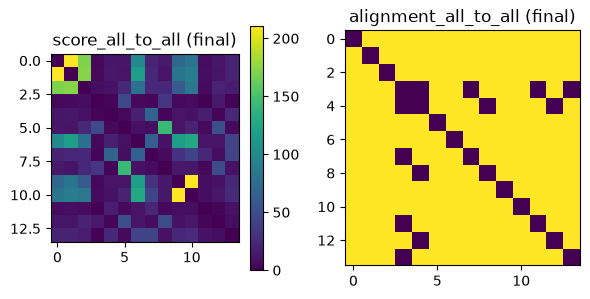

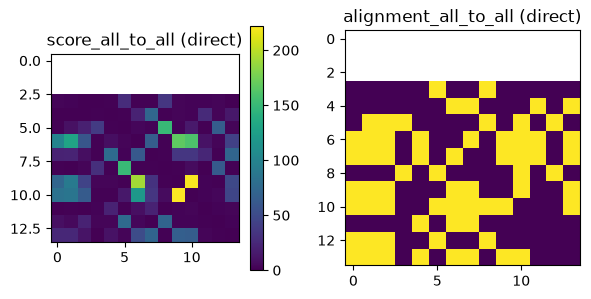

In [16]:
aligner.plot_alignment_results_geometric();

##### 3. Fit non-rigid transformation
Play with parameters until the aligned FOV_images look good. The visualization tool below can help.

We like the following **important parameters**:
- `template`=0.5
- `template_method`='image'


In [17]:
aligner.fit_nonrigid(
    template=0,  ## Same D1 reference as geometric alignment.
    ims_moving=aligner.ims_registered_geo,  ## Input images. Typically the geometrically registered images
    remappingIdx_init=aligner.remappingIdx_geo,  ## The remappingIdx between the original images (and ROIs) and ims_moving
    template_method='image',  ## 'sequential': align images to neighboring images. 'image': align to a single image, good if using geometric registration first
    method='DeepFlow',
    kwargs_method = {
        'DeepFlow': {},  ## Accuracy: Good (good in middle, poor on edges), Speed: Fast (CPU only)
        'RoMa': {  ## Accuracy: Okay (decent in middle, poor on edges), Speed: Slow (can be fast with a GPU), Notes: This method can work on the raw images without pre-registering using geometric methods.
            'model_type': 'outdoor',
        },
        'OpticalFlowFarneback': {  ## Accuracy: Varies (can sometimes be tuned to be the best as there are no edge artifacts), Speed: Medium (CPU only)
            'pyr_scale': 0.7,
            'levels': 5,
            'winsize': 256,
            'iterations': 15,
            'poly_n': 5,
            'poly_sigma': 1.5,            
        },
        'NullRegistration': {},
    },    
)

aligner.transform_images_nonrigid(FOV_images);

Finding nonrigid registration warps with mode: DeepFlow, template_method: image


Finding nonrigid registration warps: 100%|██████████| 14/14 [00:09<00:00,  1.49image/s]


Composing nonrigid warp matrices...
Applying nonrigid registration warps to images...


Final nonrigid: all-to-all alignment scores: 100%|██████████| 4/4 [00:01<00:00,  3.92chunk/s]


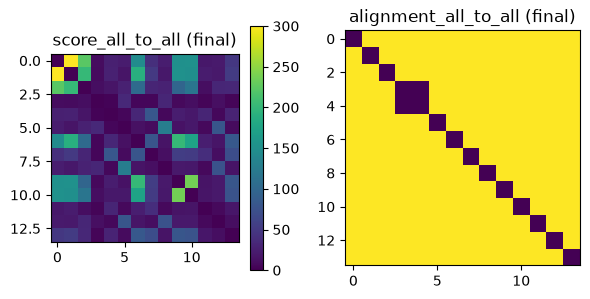

In [18]:
aligner.plot_alignment_results_nonrigid();

##### 4. Transform ROIs

In [19]:
aligner.transform_ROIs(
    ROIs=data.spatialFootprints, 
    remappingIdx=aligner.remappingIdx_nonrigid,
    # remappingIdx=aligner.remappingIdx_geo,
    normalize=True,
);

Registering ROIs...



Registering ROIs: 100%|██████████| 14/14 [00:00<00:00, 36.02it/s]


Ensure that the aligned FOVs look aligned

Pre-alignment below
Images 0–13 of 14. Use start= and count= to view another range.


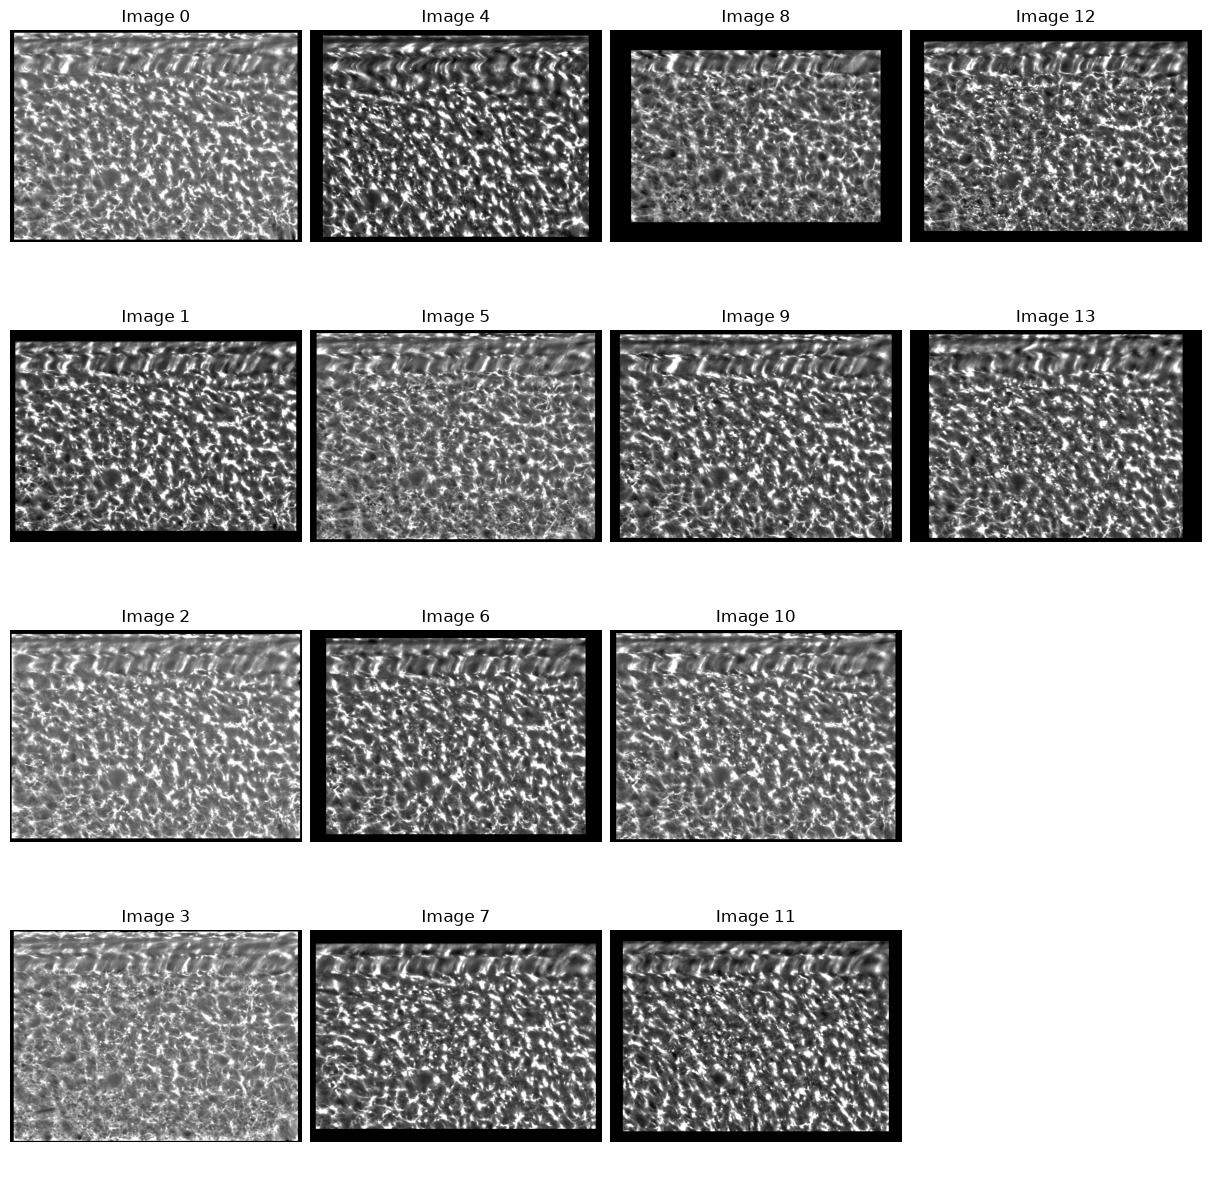

Geometric alignment below
Images 0–13 of 14. Use start= and count= to view another range.


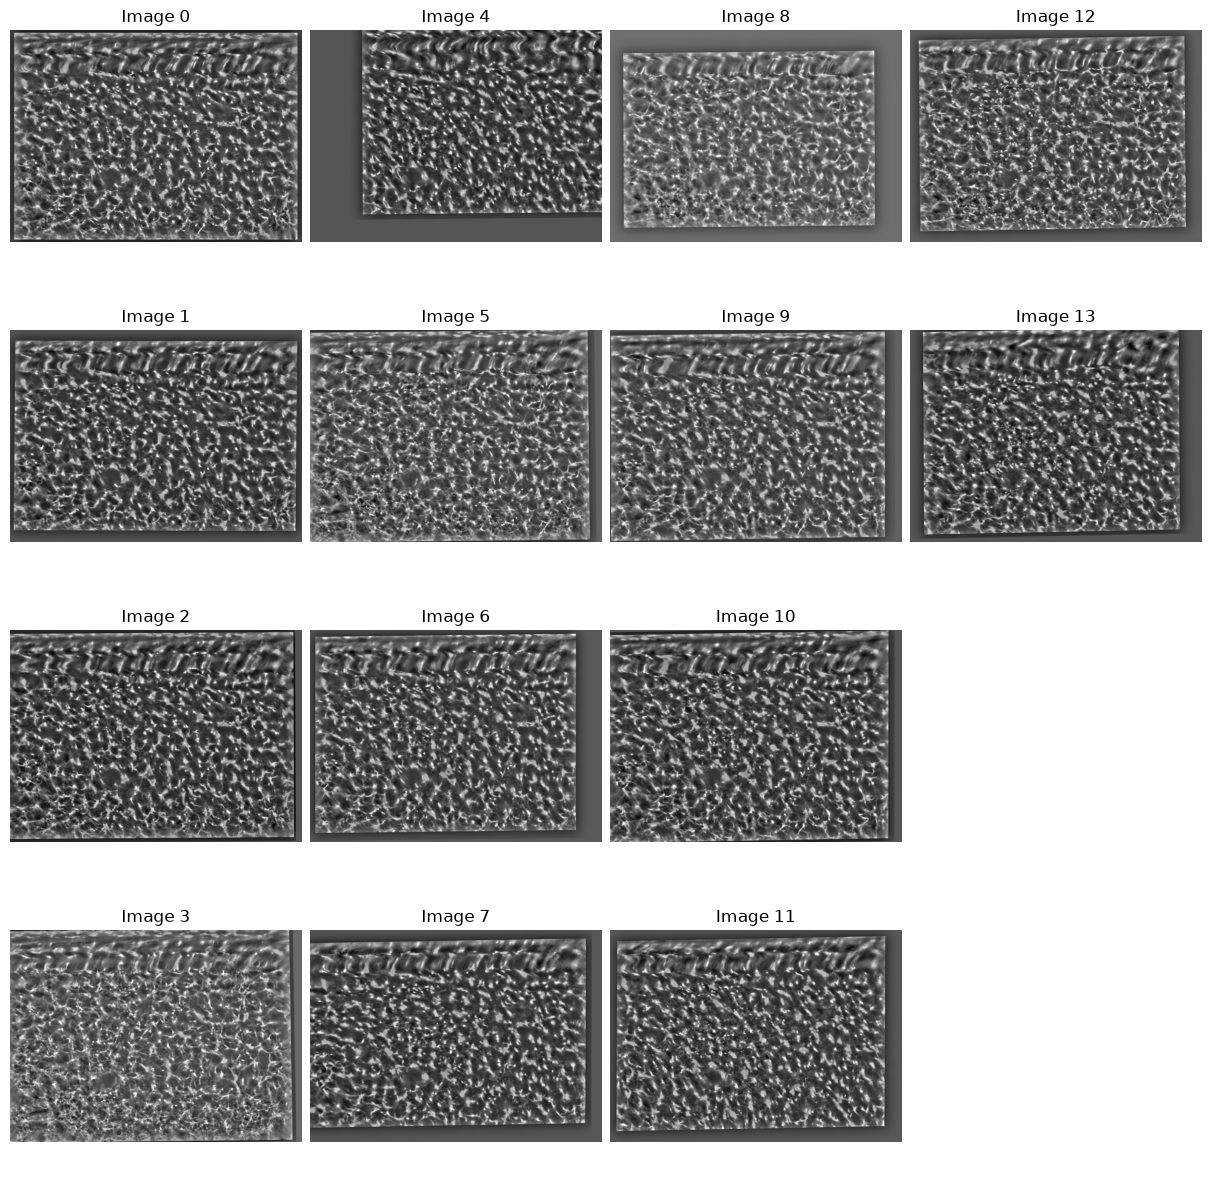

Non-rigid alignment below
Images 0–13 of 14. Use start= and count= to view another range.


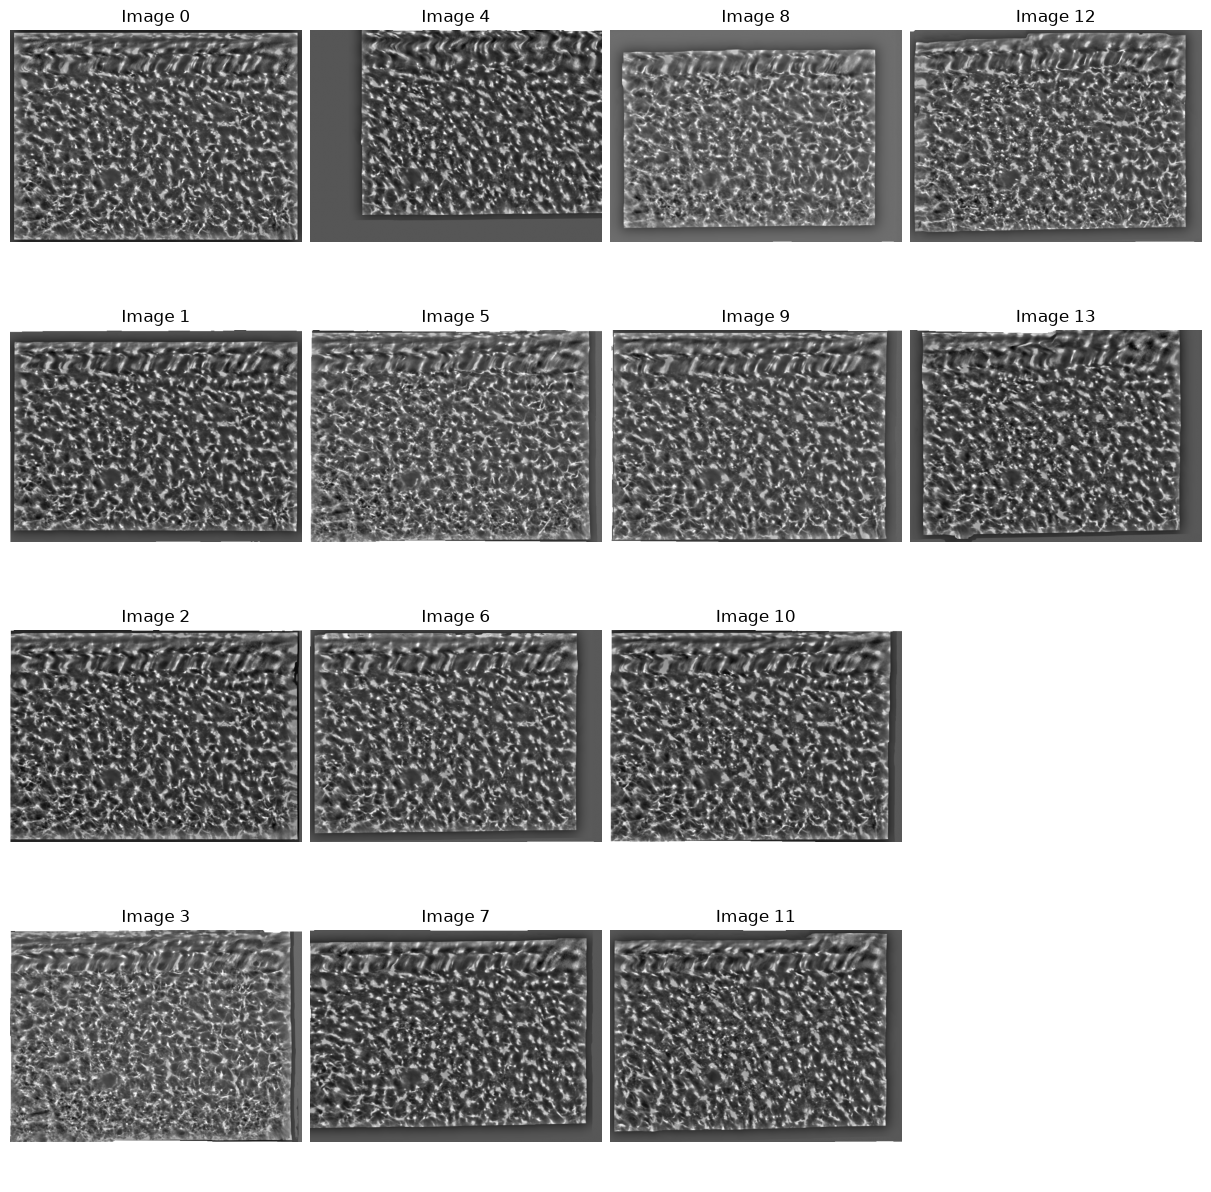

Transformed ROIs below
Images 0–13 of 14. Use start= and count= to view another range.


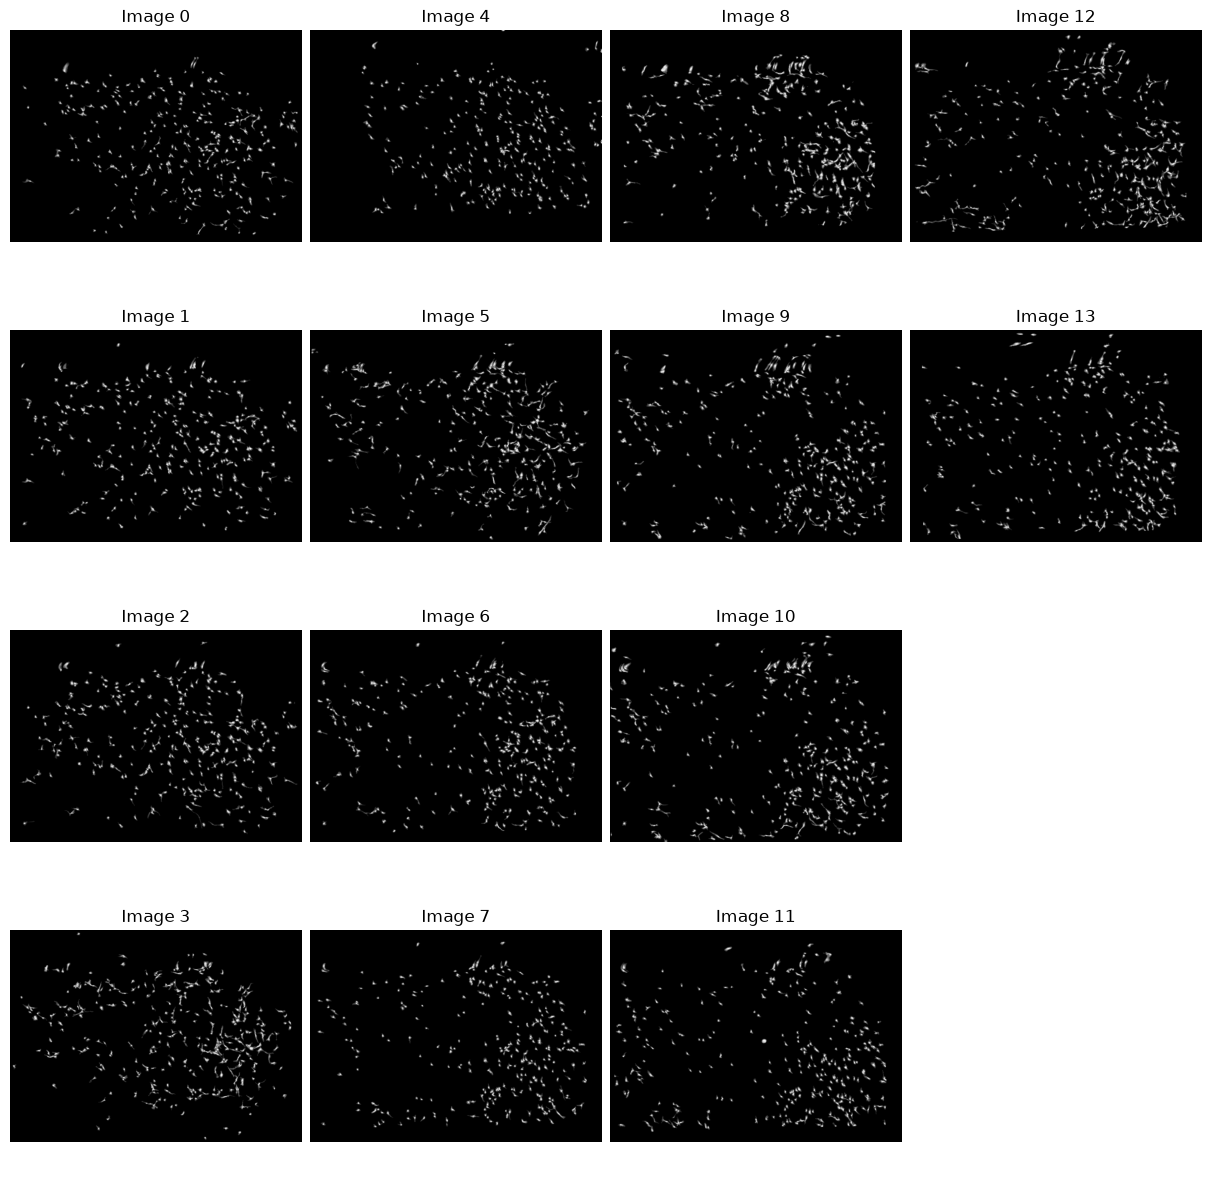

In [20]:
print(f'Pre-alignment below')
show_image_stack(data.FOV_images)
print(f'Geometric alignment below')
show_image_stack(aligner.ims_registered_geo)
print(f'Non-rigid alignment below')
show_image_stack(aligner.ims_registered_nonrigid)
print(f'Transformed ROIs below')
show_image_stack(aligner.get_ROIsAligned_maxIntensityProjection(normalize=True), clim=None)

# Blur ROIs

ROIs from different sessions with zero spatial overlap have very low probability of being considered the same ROI during the clustering step. Blurring the spatial footprint masks can increase the overlap between ROIs that drift apart from each other. It's a good idea to increase the `kernel_halfWidth` if you are working with sparsely labeled ROIs or ROIs that change/move from session to session.

In [21]:
blurrer = roicat.tracking.blurring.ROI_Blurrer(
    frame_shape=(data.FOV_height, data.FOV_width),  ## FOV height and width
    kernel_halfWidth=2,  ## The half width of the 2D gaussian used to blur the ROI masks
    plot_kernel=False,  ## Whether to visualize the 2D gaussian
)

blurrer.blur_ROIs(
    spatialFootprints=aligner.ROIs_aligned[:],
);

Preparing sparse convolution
Performing convolution for blurring


See that the blurred ROIs are overlapping each other

Images 0–13 of 14. Use start= and count= to view another range.


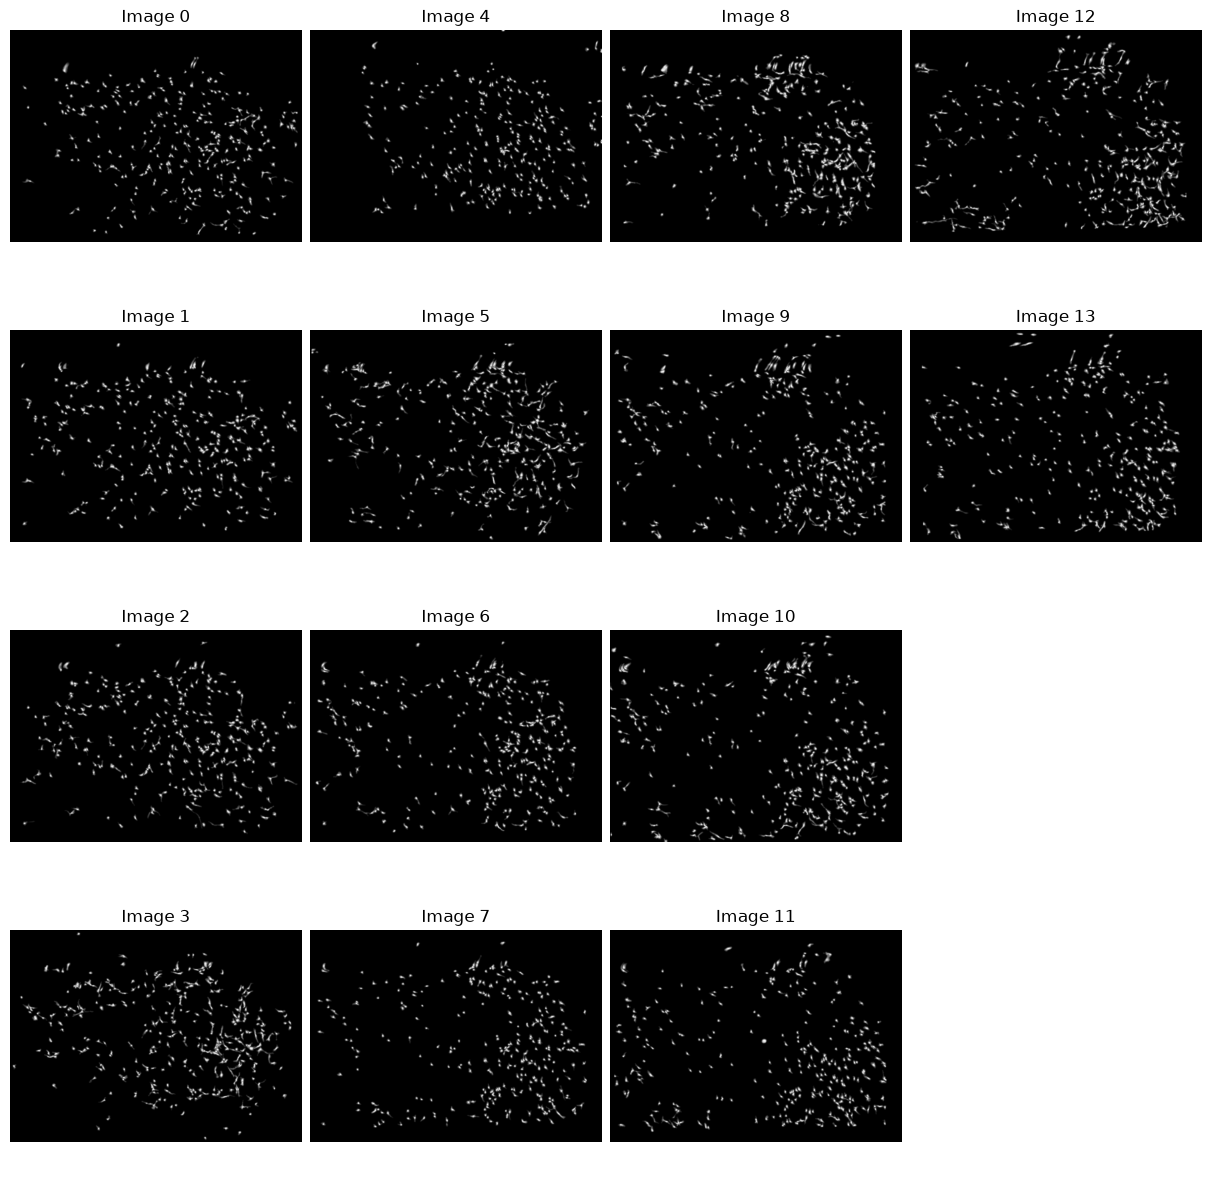

In [22]:
show_image_stack(blurrer.get_ROIsBlurred_maxIntensityProjection())

# ROInet embedding

This step passes the images of each ROI through the ROInet neural network. The inputs are the images, the output is an array describing the visual properties of each ROI.

Initialize the ROInet object. The `ROInet_embedder` class will automatically download and load a pretrained ROInet model. If you have a GPU, this step will be much faster.

In [23]:
dir_temp = tempfile.gettempdir()

roinet = roicat.ROInet.ROInet_embedder(
    device=DEVICE,  ## Which torch device to use ('cpu', 'cuda', etc.)
    dir_networkFiles=dir_temp,  ## Directory to download the pretrained network to
    download_method='check_local_first',  ## Check to see if a model has already been downloaded to the location (will skip if hash matches)
    download_url=[  ## URLs of the model, tried in order
        'https://huggingface.co/richiehakim/ROInet/resolve/9a09b3440a3b23d4857a691e771340fc19ce988b/ROInet_tracking_20220527.zip',
        'https://osf.io/x3fd2/download',
    ],
    download_hash='7a5fb8ad94b110037785a46b9463ea94',  ## Hash of the model file
    forward_pass_version='latent',  ## How the data is passed through the network
    verbose=True,  ## Whether to print updates
)

File already exists locally: /private/var/folders/k1/djbrbqcj71b4scm13dnwbwzr0000gn/T/ROInet.zip
Hash of local file matches provided hash_hex.
Extracting /private/var/folders/k1/djbrbqcj71b4scm13dnwbwzr0000gn/T/ROInet.zip to /private/var/folders/k1/djbrbqcj71b4scm13dnwbwzr0000gn/T.
Completed zip extraction.
Imported model from /private/var/folders/k1/djbrbqcj71b4scm13dnwbwzr0000gn/T/ROInet_tracking_20220527/model.py
Loaded params_model from /private/var/folders/k1/djbrbqcj71b4scm13dnwbwzr0000gn/T/ROInet_tracking_20220527/params.json
Generated network using params_model
Loaded state_dict into network from /private/var/folders/k1/djbrbqcj71b4scm13dnwbwzr0000gn/T/ROInet_tracking_20220527/ConvNext_tiny__1_0_best__simCLR.pth
Loaded network onto device mps:0


Resize ROIs and prepare a dataloader.

**Important parameters**:
- `um_per_pixel`: (same as specified in `data` object). Resolution of FOV. This is used to resize the ROIs to be relatively consistent across resolutions.

In [24]:
roinet.generate_dataloader(
    ROI_images=data.ROI_images,  ## Input images of ROIs
    um_per_pixel=data.um_per_pixel,  ## Resolution of FOV
    pref_plot=False,  ## Whether or not to plot the ROI sizes
    
    jit_script_transforms=False,  ## (advanced) Whether or not to use torch.jit.script to speed things up
    
    batchSize_dataloader=8,  ## (advanced) PyTorch dataloader batch_size
    pinMemory_dataloader=str(DEVICE).startswith('cuda'),  ## CUDA only; unsupported on Apple MPS.
    numWorkers_dataloader=mp.cpu_count(),  ## (advanced) PyTorch dataloader num_workers
    persistentWorkers_dataloader=True,  ## (advanced) PyTorch dataloader persistent_workers
    prefetchFactor_dataloader=2,  ## (advanced) PyTorch dataloader prefetch_factor
);

Starting Image Resizer


Resizing ROIs: 100%|██████████| 4200/4200 [00:00<00:00, 23412.56it/s]

Creating dataloader


Defined image transformations: Sequential(
  (0): ScaleDynamicRange(scaler_bounds=(0, 1))
  (1): Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
  (2): TileChannels(dim=-3)
)
Defined dataset
Defined dataloader


In general, you want to see that a neuron fills roughly 25-50% of the area of the image.

Images 0–15 of 1000. Use start= and count= to view another range.


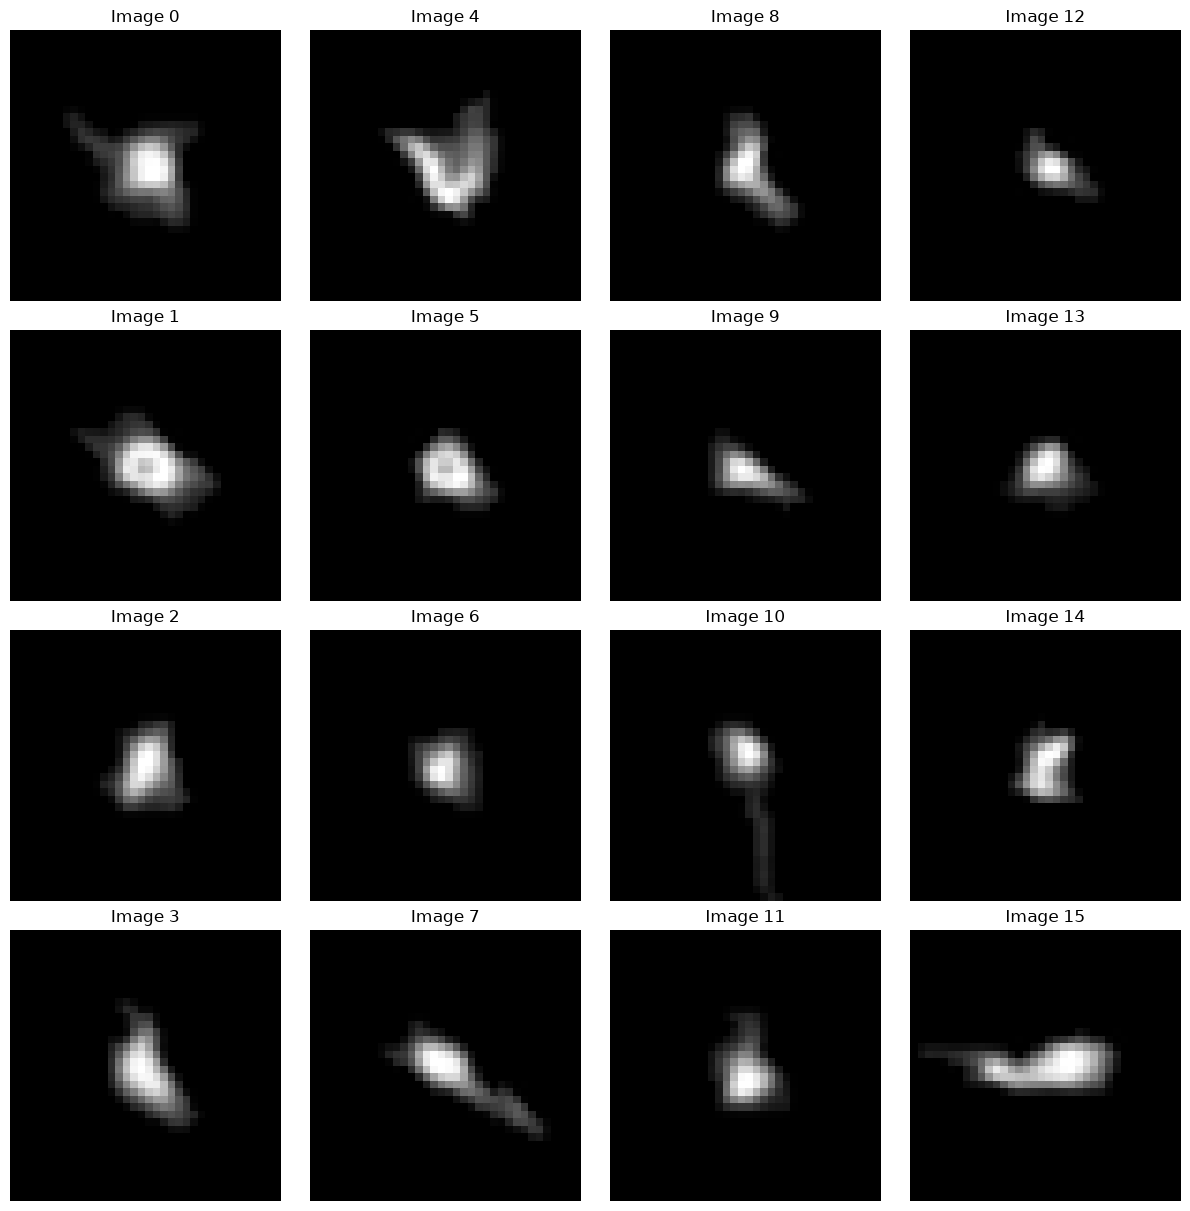

In [25]:
show_image_stack(roinet.ROI_images_rs[:1000])

Pass the data through the network. Expect for large datasets (~40,000 ROIs) that this takes around 15 minutes on CPU or 1 minute on GPU.

In [26]:
roinet.generate_latents();

starting: running data through network


100%|██████████| 525/525 [00:15<00:00, 33.92it/s]


completed: running data through network


# Scattering wavelet embedding

This is similar to the ROInet embedding in purpose.

In [27]:
swt = roicat.tracking.scatteringWaveletTransformer.SWT(
    kwargs_Scattering2D={'J': 2, 'L': 12},  ## 'J' is the number of convolutional layers. 'L' is the number of wavelet angles.
    image_shape=data.ROI_images[0].shape[1:3],  ## size of a cropped ROI image
    device=DEVICE,  ## PyTorch device
)

swt.transform(
    ROI_images=roinet.ROI_images_rs,  ## All the cropped and resized ROI images
    batch_size=100,  ## Batch size for each iteration (smaller is less memory but slower)
);

SWT initialized
Starting: SWT transform on ROIs


100%|██████████| 42/42.0 [00:01<00:00, 27.19it/s]


Completed: SWT transform on ROIs


# Compute similarities

Now we can compare the similarities of the ROIs. This includes calculating several kinds of similarities:
1. `similarities['sf']`: 'similarity spatial footprint'. The physical overlap between ROIs.
2. `similarities['nn']`: 'similarity neural network'. The similarities of the embeddings out of ROInet.
3. `similarities['swt']`: 'similarity scaterring wavelet transform'. The similarities of the embeddings out of the scattering wavelet transformer.
4. `s_sesh`: 'similarity sessions'. 0 if from the same session, 1 if from different sessions. ROIs from the same session have 0 probability of being the same.

The result of this step will be a set of pairwise similarity matrices.

Initialize the `ROI_graph` class and compute similarities.
To make computation more efficient, only ROIs within the same 'block' are compared against each other.

Computing pairwise similarity between ROIs...


100%|██████████| 24/24 [00:00<00:00, 100.15it/s]

Joining blocks into full similarity matrices...
Joining sf...
Joining nn...
Joining swt...
Joining s_sesh...


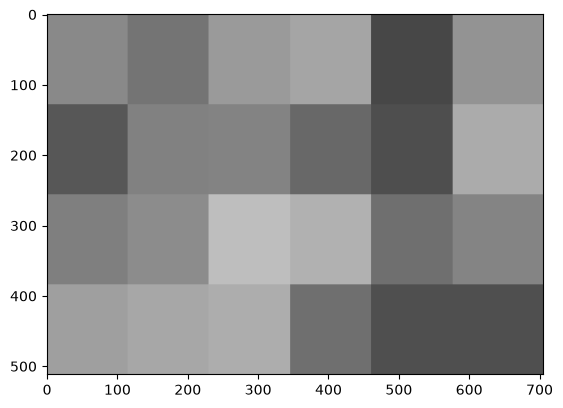

In [28]:
sim = roicat.tracking.similarity_graph.ROI_graph(
    n_workers=-1,  ## Number of CPU cores to use. -1 for all.
    frame_height=data.FOV_height,
    frame_width=data.FOV_width,
    block_height=128,  ## size of a block
    block_width=128,  ## size of a block
    verbose=True,  ## Whether to print outputs
)

sim.visualize_blocks()

similarities = sim.compute_similarity_blockwise(
    spatialFootprints=blurrer.ROIs_blurred,  ## Mask spatial footprints
    features={'nn': roinet.latents, 'swt': swt.latents},  ## Feature latents dict
    ROI_session_bool=data.session_bool,  ## Boolean array of which ROIs belong to which sessions
    spatialFootprint_maskPower=1.0,  ##  An exponent to raise the spatial footprints to to care more or less about bright pixels
);

It is useful to normalize the similarity matrices using the local ROIs.

In [29]:
sim.make_normalized_similarities(
    centers_of_mass=data.centroids,  ## ROI centroid positions
    features={'nn': roinet.latents, 'swt': swt.latents},  ## Feature latents dict
    k_max=data.n_sessions*100,  ## Maximum number of nearest neighbors to consider for the normalizing distribution
    k_min=data.n_sessions*10,  ## Minimum number of nearest neighbors to consider for the normalizing distribution
    algo_NN='kd_tree',  ## Nearest neighbors algorithm to use
    device=DEVICE,
)

Finding k-range of center of mass distance neighbors for each ROI...
Normalizing nn similarity scores...


100%|██████████| 4200/4200 [00:00<00:00, 4415.49it/s]


Normalizing swt similarity scores...


100%|██████████| 4200/4200 [00:08<00:00, 499.39it/s]


# Clustering

This step does the following:
1. Mix the similarity matrices into a single distance matrix
2. Prune the distance matrix to remove low probability connections
3. Perform clustering
4. Compute quality metrics

#### 1. Mix the similarity matrices into a single distance matrix

This step can be done either automatically, using the `clusterer.find_optimal_parameters_for_pruning` method, or manually by specifying the `mixing_params` dictionary. If you have a smaller total number of ROIs (<100 ROIs per session and/or <8 sessions), then it may be a good idea to manually play with the parameters in the next cell instead of using the automatic method.

<br></br>

##### Option A: Automatic Method (Recommended)
This method uses a two-stage approach:
1. **Naive Bayes calibration**: For each similarity feature (SF, NN, SWT), estimates the probability that a pair of ROIs is the same neuron given their similarity. The resulting calibration curves are used to estimate the sigmoid parameters (mu, b) by maximum likelihood (Platt scaling on the calibration histogram).
2. **Differential evolution (DE)**: With sigmoid parameters frozen from stage 1, optimizes the remaining 3 mixing parameters (`power_nn`, `power_swt`, `p_norm`) by minimizing the histogram overlap between the "same" and "different" pair distributions. When the dataset is large enough, a subsample of pairs is used and redrawn each generation for robustness.

The output is the optimal `mixing_params` dictionary.

<br></br>

##### Option B: Manual Method
You can also simply specify the `mixing_params` dictionary manually. This is useful if you have a good idea of what the optimal parameters are or if the automatic method is not working well. Uncomment the code block below to overwrite the `kwargs_mcdm_tmp` variable.

<br></br>

#### TROUBLESHOOTING FOR THIS STEP
- If you have any issues, just email Rich Hakim or open an issue on the github issues page.
- If you see: `'No crossover found, not plotting'`: Your data may not be easily separable. For some people, this is because the number of matching ROIs is very low compared to the number of non-matching ROIs. I recommend trying out the manual method.

In [30]:
from roicat.tracking.similarity_graph import DEFAULT_METRICS

## Initialize the clusterer object by passing the similarity matrices in
clusterer = roicat.tracking.clustering.Clusterer(
    similarities=sim.similarities_final,
    metric_configs=DEFAULT_METRICS,
    s_sesh=sim.s_sesh,
    session_bool=data.session_bool,
    verbose=1,
)

#### Automatic method

In [31]:
## Automatic method: NB calibration + freeze-sigmoid DE
kwargs_makeConjunctiveDistanceMatrix_best = clusterer.find_optimal_parameters_for_pruning(
    n_bins=None,  ## Number of bins for the pairwise distance histograms. None = heuristic.
    smoothing_window_bins=None,  ## Smoothing window for the histograms. None = heuristic.
    subsample_pairs=None,  ## Number of pairs to subsample for DE. None = auto (min 100k intra + 1M inter, otherwise full).
    bounds_findParameters={
        'power_nn': [0.0, 2.],  ## Bounds for the exponent applied to s_NN
        'power_swt': [0.0, 2.],  ## Bounds for the exponent applied to s_SWT
        'p_norm': [-5, -0.1],  ## Bounds for the p-norm p value (Minkowski) applied to mix the matrices
        'sig_nn_kwargs_mu': None,  ## Bounds for the center of the sigmoid applied to s_NN. None = derive from the observed range of the z-scored similarities.
        'sig_nn_kwargs_b': [0.5, 10.0],  ## Bounds for the slope of the sigmoid applied to s_NN
        'sig_swt_kwargs_mu': None,  ## Bounds for the center of the sigmoid applied to s_SWT. None = derive from the observed range of the z-scored similarities.
        'sig_swt_kwargs_b': [0.5, 10.0],  ## Bounds for the slope of the sigmoid applied to s_SWT
    },
    de_kwargs={
        'maxiter': 100,  ## Maximum number of DE generations
        'tol': 1e-6,  ## Convergence tolerance
        'popsize': 15,  ## Population size multiplier (actual pop = popsize * n_params)
        'mutation': (0.5, 1.5),  ## Differential weight range for dithering
        'recombination': 0.7,  ## Crossover probability
        'polish': True,  ## Run L-BFGS-B from best DE solution (often has no effect)
        'workers': -1,  ## Threads evaluating each generation in parallel (-1: all available cores). The result does not depend on it.
    },
    freeze_sigmoid=True,  ## True: sigmoid (mu, b) fixed by a maximum-likelihood grid search over the bounds above. False: (mu, b) are optimized by the DE too.
    seed=SEED,
)

Computing naive Bayes distance matrix...
  sf: P(same) range [0.0001, 0.9999], mean=0.2760
  nn: P(same) range [0.0287, 0.3616], mean=0.0454
  swt: P(same) range [0.0001, 0.1619], mean=0.0414
  Combined P(same): mean=0.2134, prior=0.1039, P(same)>0.5: 17886/85532 (20.9%)
  Sigmoid estimate for nn: mu=0.9644, b=0.50 (log-likelihood=-1.3983)
  Sigmoid estimate for swt: mu=0.6654, b=0.50 (log-likelihood=-1.2823)
  Freezing sigmoid: nn(mu=0.964, b=0.5), swt(mu=0.665, b=0.5)
Finding mixing parameters using differential evolution...


DE generations:  26%|██▌       | 26/100 [00:01<00:03, 22.88it/s, loss_best=0.336584]

Completed DE parameter search. Best value: 0.336584, evaluations: 1219, params: {'power_sf': None, 'power_nn': 0.0028279892850420207, 'power_swt': 0.00838139661500148, 'p_norm': -4.74700145183715, 'sig_sf_kwargs': None, 'sig_nn_kwargs': {'mu': 0.9643975836890084, 'b': 0.5}, 'sig_swt_kwargs': {'mu': 0.6653607998575483, 'b': 0.5}}


#### Manual method

In [32]:
# # Uncomment below to manually specify mixing parameters
# kwargs_makeConjunctiveDistanceMatrix_best = {
#     'power_sf': 1.0,   ## s_sf**power_sf   (Higher values means clustering is more sensitive to spatial overlap of ROIs)
#     'power_nn': 4.988104678381475,   ## s_NN**power_nn   (Higher values means clustering is more sensitive to visual similarity of ROIs)
#     'power_swt': 3.2306101591115177,  ## s_SWT**power_swt (Higher values means clustering is more sensitive to visual similarity of ROIs)
#     'p_norm': -3.7239759637888254,    ## norm([s_sf, s_NN, s_SWT], p=p_norm) (Higher values means clustering requires all similarity metrics to be high)
# #     'sig_sf_kwargs': {'mu':0.5, 'b':1.0},  ## Sigmoid parameters for s_sf (mu is the center, b is the slope)
#     'sig_sf_kwargs': None,
#     'sig_nn_kwargs': {'mu':0.022482651499435957, 'b':0.02659655318391102},    ## Sigmoid parameters for s_NN (mu is the center, b is the slope)
# #     'sig_nn_kwargs': None,
#     'sig_swt_kwargs': {'mu':0.10929602726304388, 'b':0.25801625013167434}, ## Sigmoid parameters for s_SWT (mu is the center, b is the slope)
# #     'sig_swt_kwargs': None,
# }

#### View mixing results
The goal is to see a **bimodal curve** in the pairwise similarities and a **clear cross-over point** (specified by the vertical dotted line) between 'same' and 'diff' pairs of ROIs.

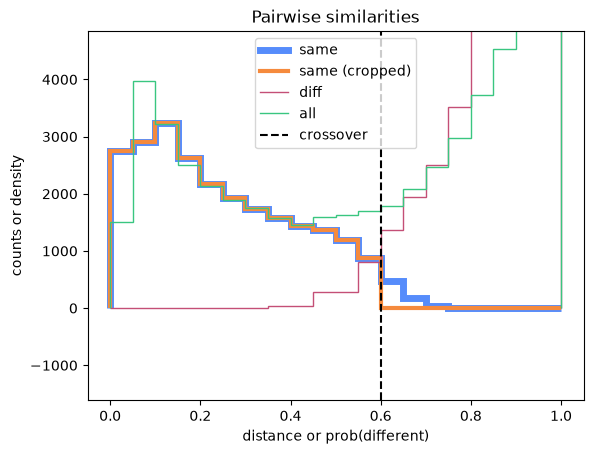

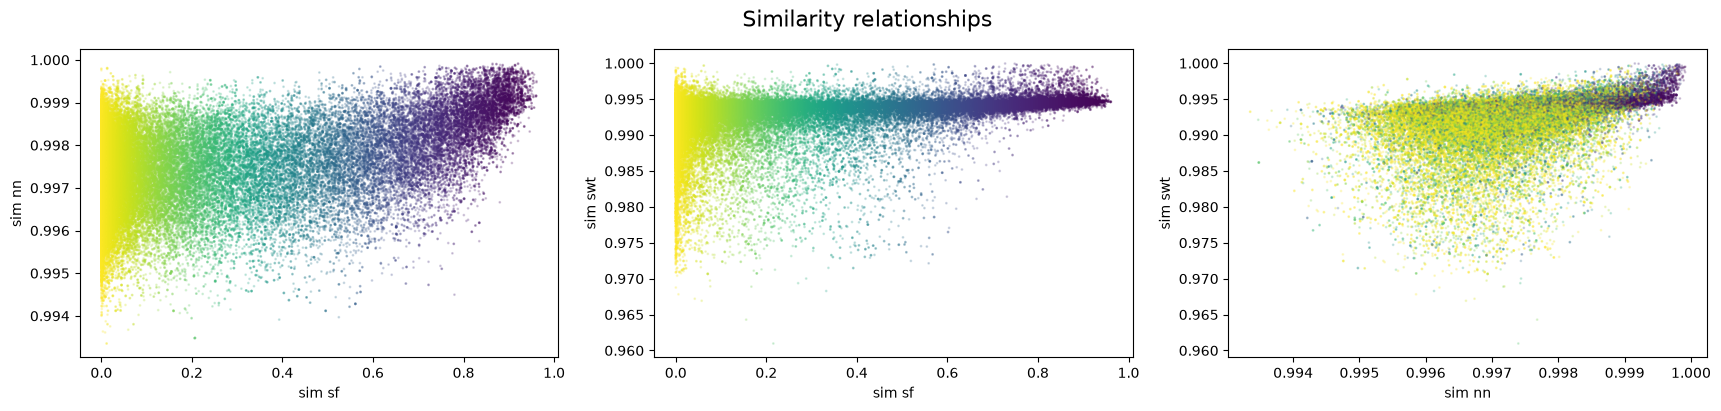

In [33]:
clusterer.plot_distSame(mixing_params=kwargs_makeConjunctiveDistanceMatrix_best)

clusterer.plot_similarity_relationships(
    max_samples=100000,  ## Make smaller if it is running too slow
    kwargs_scatter={'s':1, 'alpha':0.2},
    mixing_params=kwargs_makeConjunctiveDistanceMatrix_best
);

##### 2. Prune the distance matrix

We can remove all connections in the distance graph with probabilities of connection of less than 50%. We estimate this cutoff distance as the cross-over point between the 'same' and 'different' distributions.

**Important parameter**\
`stringency`: This value changes the threshold for pruning the distance matrix. A higher value will result in less pruning, and a lower value will result in more pruning. The value will be multiplied by the inferred threshold to get the new one. Lowering it is a weak way to raise precision, so filter ROIs by `sample_silhouette` instead.


In [34]:
clusterer.make_pruned_similarity_graphs(
    d_cutoff=None,  ## Optionally manually specify a distance cutoff
    mixing_params=kwargs_makeConjunctiveDistanceMatrix_best,
    stringency=1.0,  ## Modifies the threshold for pruning the distance matrix. Higher values result in LESS pruning. New d_cutoff = stringency * truncated d_cutoff. Lowering it is a weak way to raise precision.
    convert_to_probability=False,    
)

Pruning similarity graphs with d_cutoff = 0.6000000238418579...


##### 3. Cluster

There are two methods for clustering: The standard method `.fit` which is based on HDBSCAN, and `.fit_singleLinkage` which is single linkage clustering that never puts two ROIs from the same session into one cluster. The standard method works better when there are many sessions, and single linkage works better when there are few. As in the pipeline, this notebook uses `.fit` when there are at least 6 sessions (`n_sessions_switch`) and `.fit_singleLinkage` otherwise.

**Important parameters**:
- For standard **`.fit`** method:
1. `min_cluster_size`: If you only want ROIs clusters with at least a certain number of samples, specify here.
2. `n_iter_violationCorrection`: This parameter controls how fast this step takes. Turning it down has mild effects on quality. We use around ***6***.

- For **`.fit_singleLinkage`** method:
1. `d_clusterMerge`: The cut height: only ROI pairs closer than this distance are merged. Smaller value is more stringent. `None` uses the pruning cutoff `d_cutoff`.


In [35]:
if data.n_sessions >= 6:
    labels = clusterer.fit(
        d_conj=clusterer.dConj_pruned,  ## Input distance matrix
        session_bool=data.session_bool,  ## Boolean array of which ROIs belong to which sessions
        min_cluster_size=2,  ## Minimum number of ROIs that can be considered a 'cluster'
        min_samples=None,  ## Number of neighbors for core-point density. None defaults to min_cluster_size. Lower values reduce noise points.
        cluster_selection_method='eom',  ## (advanced) Method of cluster selection for HDBSCAN (see hdbscan documentation)
        cluster_selection_persistence=0.0,  ## (advanced) Minimum stability for a cluster to survive. Higher = fewer, more stable clusters.
        d_clusterMerge=None,  ## Distance below which clusters are merged. None defaults to d_cutoff (pruning threshold).
        rescue_noise=True,  ## Post-HDBSCAN: assign noise ROIs to nearby clusters via Kruskal DSU with cannot-link constraints.
    )

else:
    labels = clusterer.fit_singleLinkage(
        d_conj=clusterer.dConj_pruned,  ## Input distance matrix
        session_bool=data.session_bool,  ## Boolean array of which ROIs belong to which sessions
        min_cluster_size=2,  ## Minimum number of ROIs that can be considered a 'cluster'
        d_clusterMerge=None,  ## Single linkage cut height: only edges with a distance below this are merged. None defaults to d_cutoff (pruning threshold).
    )

Fitting with fast_hdbscan (group-label cannot-link constraints)
Session violations after fast_hdbscan: 0 clusters, d_clusterMerge=0.60
Noise rescue: 894/1342 noise ROIs rescued, 448 remain noise


##### 4. Quality metrics

Compute various quality scores for each cluster and each ROI.

In [36]:
## SKIP THIS STEP FOR VERY LARGE DATASETS
## Graphs omit self-edges and can have directional similarities. The corresponding
## diagnostic notices are expected: metrics ignore self-edges and use outgoing edges.
quality_metrics = clusterer.compute_quality_metrics();

## Collect results

1. Make different versions of the labels for convenience.
2. Put all the useful results and info into a dictionary to save later. ADJUST THIS ANY WAY YOU WANT.
3. Put all the class objects from the run into a dictionary to save later

In [37]:
labels_squeezed, labels_bySession, labels_bool, labels_bool_bySession, labels_dict = roicat.tracking.clustering.make_label_variants(labels=labels, n_roi_bySession=data.n_roi)

results_clusters = {
    'labels': labels_squeezed,
    'labels_bySession': labels_bySession,
    'labels_dict': labels_dict,
    'quality_metrics': clusterer.quality_metrics if hasattr(clusterer, 'quality_metrics') else None,
}

results_all = {
    "clusters":{
        "labels": roicat.util.JSON_List(labels_squeezed),
        "labels_bySession": roicat.util.JSON_List(labels_bySession),
        "labels_bool": labels_bool,
        "labels_bool_bySession": labels_bool_bySession,
        "labels_dict": roicat.util.JSON_Dict(labels_dict),
        "quality_metrics": roicat.util.JSON_Dict(clusterer.quality_metrics) if hasattr(clusterer, 'quality_metrics') else None,
    },
    "ROIs": {
        "ROIs_aligned": aligner.ROIs_aligned,
        "ROIs_raw": data.spatialFootprints,
        "frame_height": data.FOV_height,
        "frame_width": data.FOV_width,
        "idx_roi_session": np.where(data.session_bool)[1],
        "n_sessions": data.n_sessions,
    },
    "input_data": {
        "paths_stat": data.paths_stat,
        "paths_ops": data.paths_ops,
    },
}

run_data = {
    'data': data.__dict__,
    'aligner': aligner.__dict__,
    'blurrer': blurrer.__dict__,
    'roinet': roinet.__dict__,
    'swt': swt.__dict__,
    'sim': sim.__dict__,
    'clusterer': clusterer.__dict__,
}

params_used = {name: mod['params'] for name, mod in run_data.items()}

# Visualize results

In [38]:
print(f'Number of clusters: {len(np.unique(results_clusters["labels"]))}')
print(f'Number of discarded ROIs: {(np.array(results_clusters["labels"])==-1).sum()}')

Number of clusters: 667
Number of discarded ROIs: 448


Look at some of the distributions of the quality metrics.
- Silhouette score is a particularly useful one for this type of clustering. Learn more here: https://en.wikipedia.org/wiki/Silhouette_(clustering)
- The `cluster_silhouette` score is a per-cluster score. It can be used to remove whole clusters.
- The `sample_silhouette` score is a per-sample, or per-ROI, score. It can be used to remove single ROIs from clusters.
- The bottom middle panel shows the fraction of clustered ROIs that each cutoff would keep.

A good rule of thumb is to use these inclusion criteria:
- `sample_silhouette` > 0.1
- `cluster_silhouette` > somewhere around -0.1

When precision matters most, raise the `sample_silhouette` cutoff to about 0.3 first. Lowering `stringency` does little for precision. No single cutoff gives the same precision on every dataset, so look at some clusters from your own data before you settle on one. See the [ROICaT documentation](https://roicat.readthedocs.io/en/latest/inputsAndOutputs.html#quality-control) for details.

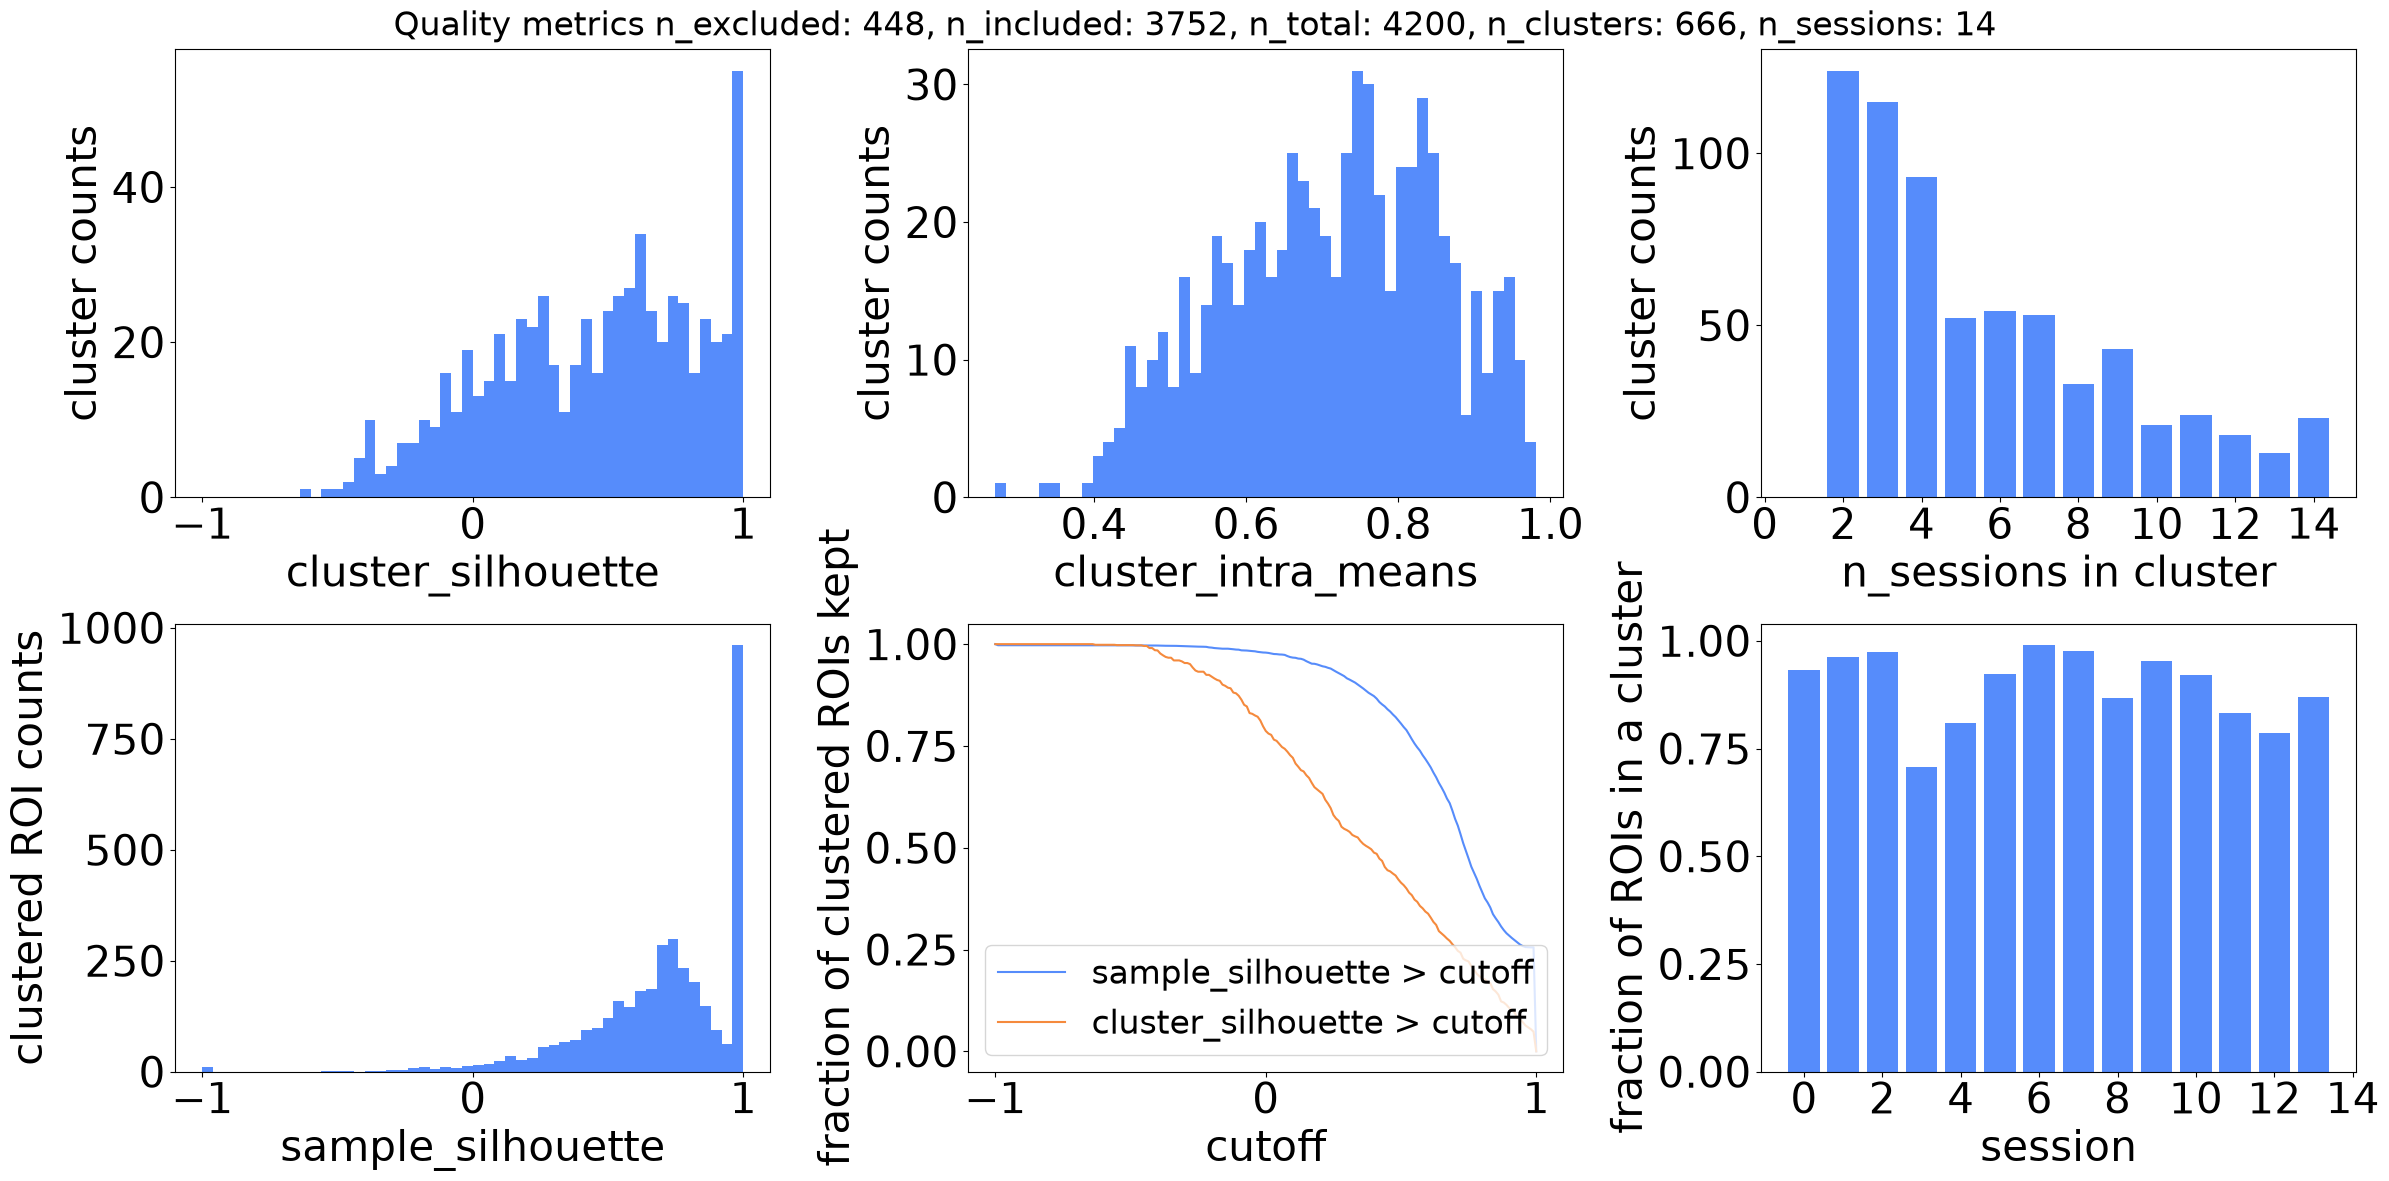

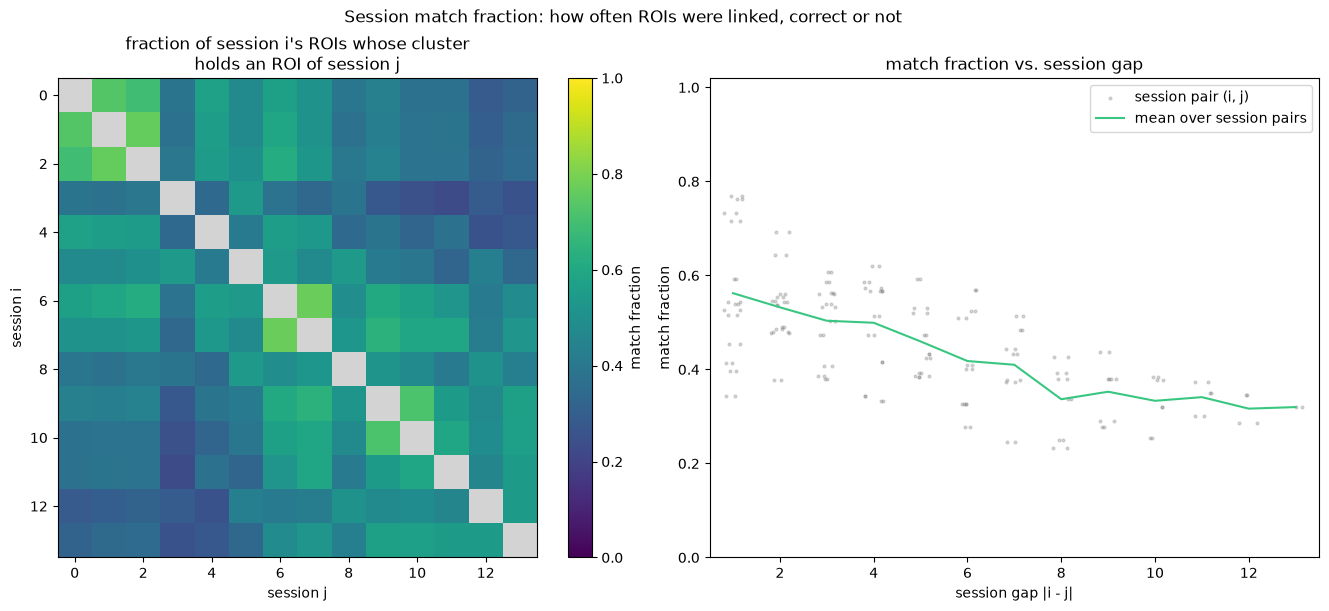

In [39]:
roicat.tracking.clustering.plot_quality_metrics(quality_metrics=quality_metrics, labels_bySession=labels_bySession);
roicat.visualization.plot_session_match_fraction(labels_bySession=labels_bySession);

Look at a color visualization of the results. ROIs of the same color are considered a part of the same cluster. The colors are assigned randomly.

Images 0–13 of 14. Use start= and count= to view another range.


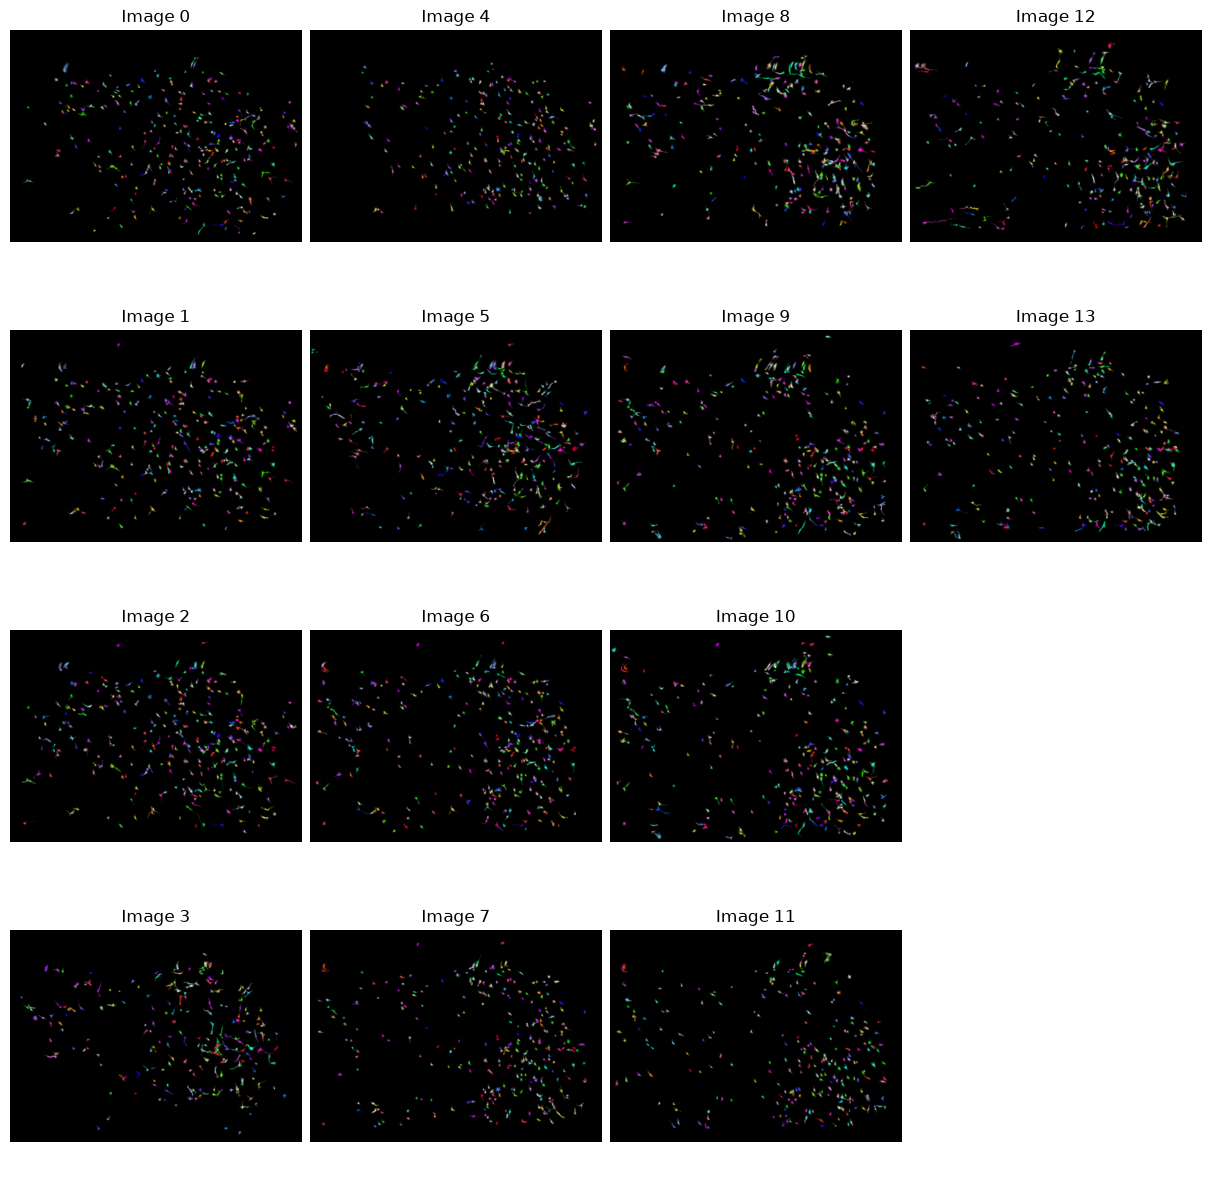

In [40]:
FOV_clusters = roicat.visualization.compute_colored_FOV(
    spatialFootprints=[r.power(1.0) for r in results_all['ROIs']['ROIs_aligned']],  ## Spatial footprint sparse arrays
    FOV_height=results_all['ROIs']['frame_height'],
    FOV_width=results_all['ROIs']['frame_width'],
    labels=results_all["clusters"]["labels_bySession"],  ## cluster labels
#     labels=(np.array(results["clusters"]["labels"])!=-1).astype(np.int64),  ## cluster labels
    # alphas_labels=confidence*1.5,  ## Set brightness of each cluster based on some 1-D array
    # alphas_labels=(np.array(clusterer.quality_metrics['cluster_silhouette']) > -0.2) * (np.array(clusterer.quality_metrics['cluster_intra_means']) > 0.3),
    # alphas_sf=np.array(clusterer.quality_metrics['sample_silhouette']) > 0,  ## Set brightness of each ROI based on some 1-D array
)

show_image_stack(FOV_clusters)

Look for bad clusters. Each cluster with a `cluster_silhouette` below the cutoff gets its own color. All other clusters are grey, and unclustered ROIs are not shown.

Images 0–13 of 14. Use start= and count= to view another range.


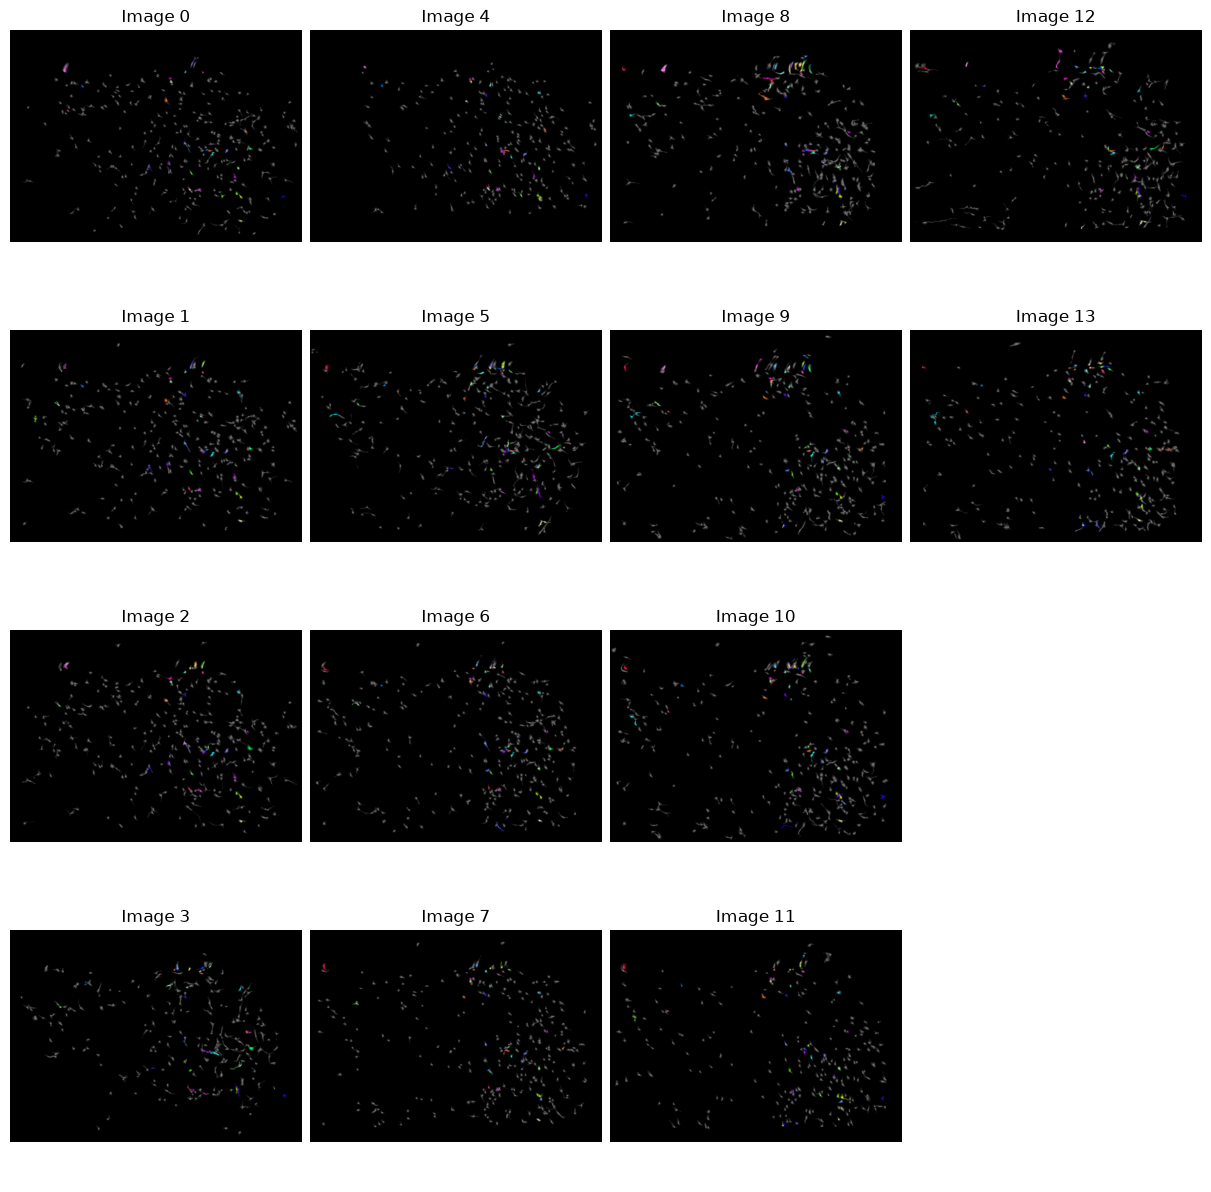

In [41]:
cutoff_cluster_silhouette = -0.1  ## Clusters with a cluster_silhouette below this value are colored

## compute_colored_FOV gives the i-th label of np.unique(labels) the i-th color of cmap. cluster_silhouette is in the same order.
assert np.array_equal(quality_metrics['cluster_labels_unique'], np.unique(labels_squeezed))
bool_bad = np.array(quality_metrics['cluster_silhouette']) < cutoff_cluster_silhouette  ## shape: (n_labels_unique,)
colors = roicat.helpers.rand_cmap(nlabels=len(bool_bad), verbose=False)(np.linspace(0, 1, len(bool_bad)))  ## shape: (n_labels_unique, 4)
colors[~bool_bad, :3] = 0.5  ## grey

FOV_badClusters = roicat.visualization.compute_colored_FOV(
    spatialFootprints=results_all['ROIs']['ROIs_aligned'],  ## Spatial footprint sparse arrays
    FOV_height=results_all['ROIs']['frame_height'],
    FOV_width=results_all['ROIs']['frame_width'],
    labels=results_all["clusters"]["labels_bySession"],  ## cluster labels
    cmap=matplotlib.colors.ListedColormap(colors),
)

show_image_stack(FOV_badClusters)

Visualize the images of ROIs from the same cluster

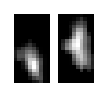

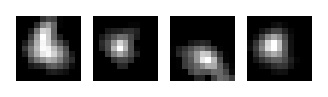

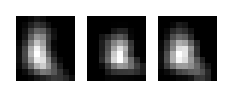

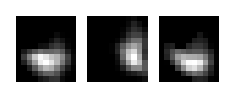

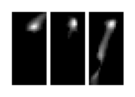

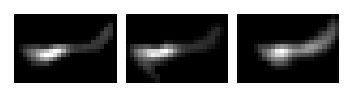

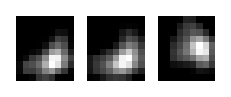

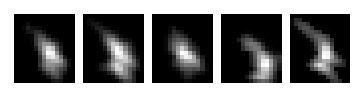

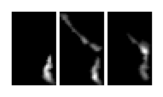

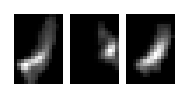

In [42]:
roicat.visualization.display_cropped_cluster_ims(
    spatialFootprints=results_all['ROIs']['ROIs_aligned'],
    labels=np.array(results_all["clusters"]["labels"]),
    FOV_height=results_all['ROIs']['frame_height'],
    FOV_width=results_all['ROIs']['frame_width'],
    n_labels_to_display=10,    
)

# Save results

In [43]:
## Define the directory to save the results to
dir_save = '/Users/cemal/Dropbox/ROICaT_results/valerio_rbp10_plane0'
name_save = 'mouse_1'

paths_save = {
    'results_clusters': str(Path(dir_save) / f'{name_save}.tracking.results_clusters.json'),
    'params_used':      str(Path(dir_save) / f'{name_save}.tracking.params_used.json'),
    'results_all':      str(Path(dir_save) / f'{name_save}.tracking.results_all.richfile.zip'),
    'run_data':         str(Path(dir_save) / f'{name_save}.tracking.run_data.richfile.zip'),
}

In [44]:
Path(dir_save).mkdir(parents=True, exist_ok=True)

roicat.helpers.json_save(obj=results_clusters, filepath=paths_save['results_clusters'])
roicat.helpers.json_save(obj=params_used, filepath=paths_save['params_used'])
roicat.util.RichFile_ROICaT(path=paths_save['results_all'], backend='zip').save(obj=results_all, overwrite=True)
roicat.util.RichFile_ROICaT(path=paths_save['run_data'], backend='zip').save(obj=run_data, overwrite=True)

RichFile(path=/Users/cemal/Dropbox/ROICaT_results/valerio_rbp10_plane0/mouse_1.tracking.run_data.richfile.zip, backend=zip, check=True, params_load={}, params_save={})

Optionally save the FOV_clusters images as an animated WebP

In [45]:
roicat.helpers.save_webp(
    array=roicat.helpers.add_text_to_images(
        images=[(f * 255).astype(np.uint8) for f in FOV_clusters], 
        text=[[f"{ii}",] for ii in range(len(FOV_clusters))], 
        font_size=3,
        line_width=10,
        position=(30, 90),
    ), 
    path=str(Path(dir_save).resolve() / 'visualization' / 'FOV_clusters_highQuality.webp'),
    frame_rate=5.0,
    loop=0,
)

# Extras

##### Demo: Importing richfiles

Simple output files are saved as .json files, which are easily handled. However, complex output files are saved using a custom format called `richfile`, which are basically just structured directories containing data files. This is a demonstration of how to import and handle richfile directories.

In [46]:
## Make a richfile object of the results_all dictionary
r = roicat.util.RichFile_ROICaT(path=paths_save['results_all'])

## You can load it
temp_results_all = r.load()

## You can load part of it by indexing into the richfile object
print(f"n_sessions: {r['ROIs']['n_sessions'].load()}")
print('')

## You can view the tree structure
r.view_tree()

n_sessions: 14

Path: /Users/cemal/Dropbox/ROICaT_results/valerio_rbp10_plane0/mouse_1.tracking.results_all.richfile.zip [/] (dict)
├── 'clusters':   (dict)
|    ├── 'labels':   (json_list)
|    ├── 'labels_bySession':   (json_list)
|    ├── 'labels_bool':   (scipy_sparray)
|    ├── 'labels_bool_bySession':   (list)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    
|    ├── 'labels_dict':   (json_dict)
|    ├── 'quality_metrics':   (json_dict)
|    
├── 'ROIs':   (dict)
|    ├── 'ROIs_aligned':   (list)
|    |    ├──   (scipy_sparray)
|    |    ├──   (scipy_sparray)
|    |    ├──   (s

#### Look at `params_used`
These were the parameters that were used in the run, they can be used to reproduce the run using the CLI by creating a params.yaml file.


In [47]:
params_used

{'data': {'__init__': {'paths_statFiles': ['/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D1/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D2/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D3/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D4/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D5/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D6/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D7/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D8/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D9/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D10/stat.npy',
    '/Users/cemal/Downloads/data__stat_ops_small__valerio_rbp10_plane0/D11/stat.npy',
    '/Users/cemal/Downlo

##### Legacy saving methods

In [48]:
dir_save = Path('/Users/cemal/Dropbox/ROICaT_results/valerio_rbp10_plane0').resolve()
name_save = Path(dir_allOuterFolders).resolve().name

path_save = dir_save / (name_save + '.ROICaT.tracking.results' + '.pkl')
print(f'path_save: {path_save}')

path_save: /Users/cemal/Library/CloudStorage/Dropbox/ROICaT_results/valerio_rbp10_plane0/data__stat_ops_small__valerio_rbp10_plane0.ROICaT.tracking.results.pkl


In [49]:
run_data_sd = {
    'data': data.serializable_dict,
    'aligner': aligner.serializable_dict,
    'blurrer': blurrer.serializable_dict,
    'roinet': roinet.serializable_dict,
    'swt': swt.serializable_dict,
    'sim': sim.serializable_dict,
    'clusterer': clusterer.serializable_dict,
}

In [50]:
roicat.helpers.pickle_save(
    obj=results_all,
    filepath=path_save,
    mkdir=True,
)

roicat.helpers.pickle_save(
    obj=run_data_sd,
    filepath=str(dir_save / (name_save + '.ROICaT.tracking.rundata' + '.pkl')),
    mkdir=True,
)


Optionally save results as a matlab file.

In [51]:
roicat.helpers.matlab_save(
    obj=results_all,
    filepath=str(dir_save / (name_save + '.ROICaT.tracking.results' + '.mat')),
)

## Save more figures

In [52]:
### Save animations of the FOVs at different stages of alignment
roicat.helpers.save_webp(
    array=roicat.helpers.add_text_to_images(
        images=[(np.clip(np.nan_to_num(f / max(np.nanmax(f), 1e-8), nan=0.0), 0, 1) * 255).astype(np.uint8) for f in FOV_images], 
        text=[[f"{ii}",] for ii in range(len(FOV_clusters))], 
        font_size=3,
        line_width=10,
        position=(30, 90),
    ), 
    path=str(Path(dir_save).resolve() / 'visualization' / 'FOV_images.webp'),
    frame_rate=5,
    loop=0,
)

roicat.helpers.save_webp(
    array=roicat.helpers.add_text_to_images(
        images=[(np.clip(np.nan_to_num(f / max(np.nanmax(f), 1e-8), nan=0.0), 0, 1) * 255).astype(np.uint8) for f in aligner.ims_registered_geo], 
        text=[[f"{ii}",] for ii in range(len(FOV_clusters))], 
        font_size=3,
        line_width=10,
        position=(30, 90),
    ), 
    path=str(Path(dir_save).resolve() / 'visualization' / 'FOV_images_aligned_geometric.webp'),
    frame_rate=5,
    loop=0,
)

roicat.helpers.save_webp(
    array=roicat.helpers.add_text_to_images(
        images=[(np.clip(np.nan_to_num(f / max(np.nanmax(f), 1e-8), nan=0.0), 0, 1) * 255).astype(np.uint8) for f in aligner.ims_registered_nonrigid], 
        text=[[f"{ii}",] for ii in range(len(FOV_clusters))], 
        font_size=3,
        line_width=10,
        position=(30, 90),
    ), 
    path=str(Path(dir_save).resolve() / 'visualization' / 'FOV_images_aligned_nonrigid.webp'),
    frame_rate=5,
    loop=0,
)

roicat.helpers.save_webp(
    array=roicat.helpers.add_text_to_images(
        images=[(np.clip(np.nan_to_num(f / max(np.nanmax(f), 1e-8), nan=0.0), 0, 1) * 255).astype(np.uint8) for f in aligner.get_ROIsAligned_maxIntensityProjection(normalize=True)], 
        text=[[f"{ii}",] for ii in range(len(FOV_clusters))], 
        font_size=3,
        line_width=10,
        position=(30, 90),
    ), 
    path=str(Path(dir_save).resolve() / 'visualization' / 'FOV_ROIs_aligned.webp'),
    frame_rate=5,
    loop=0,
)